# Shelf-level Forecasting and Inventory Alert System for Corporacion Favorita Sales 

## Import Libraries

In [1]:
# Install py7zr
!pip install py7zr

# Install Google Gen AI package (the older google-generativeai package reached end of life on 30 Nov 2025)
!pip install -q google-genai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [py7zr]32m5/6 [py7zr]


In [2]:
import pandas as pd
import numpy as np
import os
import py7zr
import warnings
warnings.filterwarnings('ignore')

# LLM for Alert Generation
from google import genai

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Machine Learning Models
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

# Time Series Models
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet

# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.preprocessing import MinMaxScaler

# Suppress warnings
import logging
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # 3=error only
logging.getLogger('tensorflow').setLevel(logging.ERROR)

logging.getLogger('prophet').setLevel(logging.ERROR)
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)

logging.getLogger('statsmodels').setLevel(logging.ERROR)

### Secure API Key Loading

In [3]:
## To load API key from Kaggle Secrets

def load_api_key_secure(secret_name='GEMINI_API_KEY'):
    if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ:
        try:
            from kaggle_secrets import UserSecretsClient
            user_secrets = UserSecretsClient()
            api_key = user_secrets.get_secret(secret_name)
            print(f"Loaded {secret_name} from Kaggle Secrets")
            return api_key
        except Exception as e:
            print(f"Error: {e}")
            return None
    else:
        # Loading from local environment
        from dotenv import load_dotenv
        load_dotenv()
        return os.environ.get(secret_name)


GEMINI_API_KEY = load_api_key_secure('GEMINI_API_KEY')

Loaded GEMINI_API_KEY from Kaggle Secrets


## Load Data

### Create function to import .csv files inside .7z archives

This function loads a single .csv inside a .7z archive directly into a dataframe.

In [4]:
def load_7z_csv(file_path, date_columns=None, parse_dates=False):

    import tempfile
    import os
    
    with tempfile.TemporaryDirectory() as tmpdir:
        with py7zr.SevenZipFile(file_path, mode='r') as archive:
            # Extract all files to temp directory
            archive.extractall(path=tmpdir)
        
        # Find the extracted CSV file
        extracted_files = os.listdir(tmpdir)
        
        if not extracted_files:
            raise ValueError(f"No files found in archive: {file_path}")
        
        # Read the file
        csv_path = os.path.join(tmpdir, extracted_files[0])
    
        
        # Parse dates if requested
        if parse_dates:
            if date_columns is not None:
                df = pd.read_csv(csv_path, parse_dates=date_columns)
            else:
                df = pd.read_csv(csv_path, parse_dates=True)
        else:
            df = pd.read_csv(csv_path)
    
    return df

In [5]:
# test_path = "/kaggle/input/favorita-grocery-sales-forecasting/test.csv.7z"
# test = load_7z_csv(test_path)
# print("Test shape:", test.shape)


train_path = "/kaggle/input/competitions/favorita-grocery-sales-forecasting/train.csv.7z"
train = load_7z_csv(train_path, date_columns=['date'], parse_dates=True)
print("Train shape:", train.shape)


items_path = "/kaggle/input/competitions/favorita-grocery-sales-forecasting/items.csv.7z"
items = load_7z_csv(items_path)
print("Items shape:", items.shape)

 
holidays_path = "/kaggle/input/competitions/favorita-grocery-sales-forecasting/holidays_events.csv.7z"
holidays = load_7z_csv(holidays_path, date_columns=['date'], parse_dates=True)
print("Holiday events shape:", holidays.shape)


oil_path = "/kaggle/input/competitions/favorita-grocery-sales-forecasting/oil.csv.7z"
oil = load_7z_csv(oil_path, date_columns=['date'], parse_dates=True)
print("Oil shape:", oil.shape)


stores_path = "/kaggle/input/competitions/favorita-grocery-sales-forecasting/stores.csv.7z"
stores = load_7z_csv(stores_path)
print("Stores shape:", stores.shape)


transc_path = "/kaggle/input/competitions/favorita-grocery-sales-forecasting/transactions.csv.7z"
transactions = load_7z_csv(transc_path, date_columns=['date'], parse_dates=True)
print("Transactions shape:", transactions.shape)

Train shape: (125497040, 6)
Items shape: (4100, 4)
Holiday events shape: (350, 6)
Oil shape: (1218, 2)
Stores shape: (54, 5)
Transactions shape: (83488, 3)


### Downcast float and integer type columns to lower type

Downcast integer and float columns to smaller dtypes to reduce memory usage

In [6]:
import pandas as pd
import numpy as np

def downcast_dtypes(df, verbose=True):
    start_mem = df.memory_usage().sum() / 1024**2
    
    df_downcasted = df.copy()
    
    for col in df_downcasted.columns:
        col_type = df_downcasted[col].dtype
        
        if pd.api.types.is_integer_dtype(col_type):
            df_downcasted[col] = pd.to_numeric(df_downcasted[col], downcast='integer')
        
        elif pd.api.types.is_float_dtype(col_type):
            df_downcasted[col] = pd.to_numeric(df_downcasted[col], downcast='float')
    
    end_mem = df_downcasted.memory_usage().sum() / 1024**2
    
    if verbose:
        print(f"Memory usage before: {start_mem:.2f} MB")
        print(f"Memory usage after: {end_mem:.2f} MB")
        print(f"Reduced by {100 * (start_mem - end_mem) / start_mem:.1f}%")
    
    return df_downcasted


In [7]:
# Downcast dataframes to lower data type   

# test = downcast_dtypes(test, verbose=True)
train = downcast_dtypes(train, verbose=True)
items = downcast_dtypes(items, verbose=True)
holidays = downcast_dtypes(holidays, verbose=True)
oil = downcast_dtypes(oil, verbose=True)
stores = downcast_dtypes(stores, verbose=True)
transactions = downcast_dtypes(transactions, verbose=True)

Memory usage before: 5744.80 MB
Memory usage after: 3470.82 MB
Reduced by 39.6%
Memory usage before: 0.13 MB
Memory usage after: 0.06 MB
Reduced by 53.1%
Memory usage before: 0.01 MB
Memory usage after: 0.01 MB
Reduced by 0.0%
Memory usage before: 0.02 MB
Memory usage after: 0.01 MB
Reduced by 24.8%
Memory usage before: 0.00 MB
Memory usage after: 0.00 MB
Reduced by 33.0%
Memory usage before: 1.91 MB
Memory usage after: 0.88 MB
Reduced by 54.2%


## Data Preprocessing

### Prepare the Corporacion Favorita Grocery Sales Dataset 

A sample of 10 stores and 10 items is drawn by stratified random sampling: stores are stratified by cluster and items by product family, with each stratum's share of the sample proportional to its size.

The sample is chosen using 2015 sales only, before the 2016–2017 modelling period, so the test period plays no part in the selection. Stores must have traded on at least 95% of days in 2015, and items must have sold on at least half of the store-days in the sampled stores, so that every series has enough sales to model.

In [8]:
class FavoritaDataPreparer:

    @staticmethod
    def _allocate(counts, n):
        """Split n across strata in proportion to their size (largest remainder), never above a stratum's size."""
        counts = counts[counts > 0]
        n = min(n, int(counts.sum()))
        quota = counts / counts.sum() * n
        alloc = np.minimum(np.floor(quota).astype(int), counts)
        while alloc.sum() < n:
            gap = (quota - alloc).where(counts - alloc > 0, -np.inf)
            alloc[gap.idxmax()] += 1
        return alloc[alloc > 0]

    def sample_items_stores(self, train, items, stores, n_items=10, n_stores=10,
                            selection_end='2015-12-31', min_active_share=0.5, random_state=42):
        print("Stratified Sampling....")
        rng = np.random.default_rng(random_state)

        # Use only the year before the modelling period (2016-2017) to choose the sample,
        # so that the test period plays no part in the selection
        selection_end = pd.Timestamp(selection_end)
        history = train[(train['date'] > selection_end - pd.Timedelta(days=365)) & (train['date'] <= selection_end)]
        n_days = history['date'].nunique()
        print(f"Selection window: {history['date'].min().date()} to {history['date'].max().date()} ({n_days} days)")

        ## 1. Stratified sampling of stores by cluster
        print(f"\nSampling {n_stores} stores across clusters...")

        # Stores must have traded on at least 95% of days in the selection window
        store_days = history.groupby('store_nbr')['date'].nunique()
        eligible_stores = stores[stores['store_nbr'].map(store_days).fillna(0) >= 0.95 * n_days]

        cluster_counts = eligible_stores['cluster'].value_counts()
        print(f"\nStore cluster distribution (eligible stores):")
        print(cluster_counts)

        sampled_stores = []
        for cluster, k in self._allocate(cluster_counts, n_stores).items():
            candidates = eligible_stores.loc[eligible_stores['cluster'] == cluster, 'store_nbr'].to_numpy()
            sampled_stores.extend(int(s) for s in rng.choice(candidates, size=k, replace=False))

        print(f"\nSampled {len(sampled_stores)} stores across "
              f"{stores[stores['store_nbr'].isin(sampled_stores)]['cluster'].nunique()} clusters")

        ## 2. Stratified sampling of items by family
        print(f"\nSampling {n_items} items across product families...")

        # Items must sell on at least min_active_share of the store-days in the sampled stores
        history_sampled = history[history['store_nbr'].isin(sampled_stores)]
        sale_days = history_sampled.groupby('item_nbr').size()
        active_share = sale_days / (n_days * len(sampled_stores))
        eligible_items = items[items['item_nbr'].map(active_share).fillna(0) >= min_active_share]

        family_counts = eligible_items['family'].value_counts()
        print(f"\nProduct family distribution (eligible items):")
        print(family_counts)

        sampled_items = []
        for family, k in self._allocate(family_counts, n_items).items():
            candidates = eligible_items.loc[eligible_items['family'] == family, 'item_nbr'].to_numpy()
            sampled_items.extend(int(i) for i in rng.choice(candidates, size=k, replace=False))

        print(f"\nSampled {len(sampled_items)} items across "
              f"{items[items['item_nbr'].isin(sampled_items)]['family'].nunique()} families")

        train_filtered = train[
            (train['item_nbr'].isin(sampled_items)) &
            (train['store_nbr'].isin(sampled_stores))
        ].copy()

        print(f"\nFiltered data shape: {train_filtered.shape}")
        print(f"Date range: {train_filtered['date'].min()} to {train_filtered['date'].max()}")

        return train_filtered, sampled_items, sampled_stores

    def filter_last_2years(self, df):
        df['year'] = df['date'].dt.year
        df_filtered = df[df['year'].isin([2016, 2017])].copy()
        print(f"\nFiltered to 2016-2017: {df_filtered.shape}")
        return df_filtered


In [9]:
preparer = FavoritaDataPreparer()
train_filtered, top_items, top_stores = preparer.sample_items_stores(train, items, stores)
train_filtered = preparer.filter_last_2years(train_filtered)

Stratified Sampling....
Selection window: 2015-01-01 to 2015-12-31 (364 days)

Sampling 10 stores across clusters...

Store cluster distribution (eligible stores):
cluster
3     7
10    5
13    4
15    4
6     4
14    4
1     3
4     3
8     3
9     2
11    2
12    1
7     1
2     1
16    1
5     1
17    1
Name: count, dtype: int64

Sampled 10 stores across 9 clusters

Sampling 10 items across product families...

Product family distribution (eligible items):
family
GROCERY I              548
CLEANING               222
BEVERAGES              197
DAIRY                  101
DELI                    65
PERSONAL CARE           61
BREAD/BAKERY            43
HOME CARE               30
PRODUCE                 28
POULTRY                 15
FROZEN FOODS            11
PREPARED FOODS          10
EGGS                     9
LIQUOR,WINE,BEER         8
GROCERY II               2
SEAFOOD                  2
HOME AND KITCHEN II      1
Name: count, dtype: int64

Sampled 10 items across 5 families

Filtere

### Perform data quality checks and cleaning

In [10]:
class DataQualityChecker:

    @staticmethod
    def check_and_clean(df):
        print("\nCheck Data Quality....")

        print("\nMissing values:")
        print(df.isna().sum())

        negative_sales = (df['unit_sales'] < 0).sum()
        print(f"\nNegative sales: {negative_sales} ({negative_sales/len(df)*100:.2f}%)")
        df['unit_sales'] = df['unit_sales'].clip(lower=0)

        if "onpromotion" in df.columns:
            df['onpromotion'] = df['onpromotion'].fillna(False)

        q99 = df['unit_sales'].quantile(0.99)
        outliers = (df['unit_sales'] > q99).sum()
        print(f"Outliers (>99th percentile): {outliers} ({outliers/len(df)*100:.2f}%)")

        return df

    @staticmethod
    def fill_missing_dates(df, transactions):
        """train.csv has no rows for days with zero sales. Add one row per item-store per calendar day,
        so that lags and rolling windows count days (not rows) and zero-sales days are modelled.
        Days before an item's first sale in a store are not added. is_open marks whether the store traded."""
        print("\nFilling days with no recorded sales....")
        df = df.drop(columns=['id'], errors='ignore')

        dates = pd.date_range(df['date'].min(), df['date'].max(), freq='D')
        first_sale = (df.groupby(['item_nbr', 'store_nbr'], as_index=False)['date'].min()
                        .rename(columns={'date': 'first_sale'}))
        grid = first_sale.merge(pd.DataFrame({'date': dates}), how='cross')
        grid = grid[grid['date'] >= grid['first_sale']].drop(columns='first_sale')

        full = grid.merge(df, on=['date', 'item_nbr', 'store_nbr'], how='left')
        recorded = full['unit_sales'].notna()

        # A store is open if it reported transactions or sold anything that day (e.g. closed on 25 December)
        tx_days = transactions[['date', 'store_nbr']].drop_duplicates().assign(tx=1)
        full = full.merge(tx_days, on=['date', 'store_nbr'], how='left')
        any_sales = recorded.groupby([full['date'], full['store_nbr']]).transform('any')
        full['is_open'] = (full['tx'].notna() | any_sales).astype(int)
        full = full.drop(columns='tx')

        full['unit_sales'] = full['unit_sales'].fillna(0)
        full['onpromotion'] = full['onpromotion'].fillna(False).astype(bool)
        full['year'] = full['date'].dt.year

        print(f"Rows with sales: {recorded.sum():,} | zero-sales days added: {(~recorded).sum():,} "
              f"| store-closed rows: {(full['is_open'] == 0).sum():,}")
        print(f"Shape after filling: {full.shape}")
        return full.sort_values(['item_nbr', 'store_nbr', 'date']).reset_index(drop=True)

In [11]:
# Perform data quality checks
checker = DataQualityChecker()
train_filtered = checker.check_and_clean(train_filtered)
train_filtered = checker.fill_missing_dates(train_filtered, transactions)

# Create a copy of the filtered train dataset to be used for training SARIMA, LSTM, Prophet
# (it is cut to the training period after the train/test split below)
train_for_sarima_lstm_prophet = train_filtered.copy()


Check Data Quality....

Missing values:
id             0
date           0
store_nbr      0
item_nbr       0
unit_sales     0
onpromotion    0
year           0
dtype: int64

Negative sales: 5 (0.01%)
Outliers (>99th percentile): 426 (0.99%)

Filling days with no recorded sales....
Rows with sales: 43,220 | zero-sales days added: 12,722 | store-closed rows: 190
Shape after filling: (55942, 7)


### Exploratory Data Analysis

In [12]:
class EDAAnalyzer:

    @staticmethod
    def analyze_sales_trends(df, items_df=None):
        print("\nSales Trends Analysis....")

        # Work on a copy so the analysis does not add columns to the modelling data
        df_temp = df.merge(items_df[['item_nbr', 'family']], on='item_nbr', how='left') if items_df is not None else df

        # Analyze if family column exists
        if 'family' in df_temp.columns:
            # Sales by family
            family_sales = df_temp.groupby('family')['unit_sales'].agg(['sum', 'mean', 'count'])
            print("\nTop 5 families by total sales:")
            print(family_sales.sort_values('sum', ascending=False).head())

        # Time trends
        daily_sales = df.groupby('date')['unit_sales'].sum()
        print(f"\nAverage daily sales: {daily_sales.mean():.2f}")
        print(f"Std deviation: {daily_sales.std():.2f}")

        return df

    @staticmethod
    def analyze_seasonality(df):
        print("\nSeasonality Analysis.... ")

        # Create temporary columns for analysis only
        df_temp = df.copy()
        df_temp['dow'] = df_temp['date'].dt.dayofweek
        df_temp['month'] = df_temp['date'].dt.month

        # Weekly pattern
        weekly_pattern = df_temp.groupby('dow')['unit_sales'].mean()
        print("\nAverage sales by day of week:")
        days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
        for i, day in enumerate(days):
            print(f"  {day}: {weekly_pattern[i]:.2f}")

        # Monthly pattern
        monthly_pattern = df_temp.groupby('month')['unit_sales'].mean()
        print("\nAverage sales by month:")
        months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
        for i, month in enumerate(months, 1):
            if i in monthly_pattern.index:
                print(f"  {month}: {monthly_pattern[i]:.2f}")

        return df

    @staticmethod
    def analyze_promotions(df):
        if 'onpromotion' not in df.columns:
            print("\nPromotional Impact...")
            print("No promotion data available")
            return df

        print("\nPromotional Impact....")

        promo_impact = df.groupby('onpromotion')['unit_sales'].agg(['mean', 'median', 'count'])
        print("\nSales: Promotion vs No Promotion")
        print(promo_impact)

        if True in promo_impact.index and False in promo_impact.index:
            lift = (promo_impact.loc[True, 'mean'] / promo_impact.loc[False, 'mean'] - 1) * 100
            print(f"\nPromotional lift: {lift:.2f}%")

            promo_pct = promo_impact.loc[True, 'count'] / promo_impact['count'].sum() * 100
            print(f"Percentage of sales on promotion: {promo_pct:.1f}%")

        return df

In [13]:
# Perform EDA
eda = EDAAnalyzer()
train_filtered = eda.analyze_sales_trends(train_filtered, items)
train_filtered = eda.analyze_seasonality(train_filtered)
train_filtered = eda.analyze_promotions(train_filtered)


Sales Trends Analysis....

Top 5 families by total sales:
                     sum      mean  count
family                                   
GROCERY I  154745.000000  6.894409  22445
DAIRY       42288.000000  7.143243   5920
BEVERAGES   37452.000000  3.166117  11829
CLEANING    23893.000000  2.018331  11838
DELI        13394.916992  3.425810   3910

Average daily sales: 459.08
Std deviation: 132.49

Seasonality Analysis.... 

Average sales by day of week:
  Monday: 4.51
  Tuesday: 4.35
  Wednesday: 4.44
  Thursday: 4.09
  Friday: 4.71
  Saturday: 6.14
  Sunday: 5.74

Average sales by month:
  Jan: 5.42
  Feb: 5.35
  Mar: 5.01
  Apr: 4.09
  May: 3.72
  Jun: 3.90
  Jul: 4.93
  Aug: 5.01
  Sep: 4.82
  Oct: 5.07
  Nov: 5.74
  Dec: 6.73

Promotional Impact....

Sales: Promotion vs No Promotion
                mean  median  count
onpromotion                        
False        4.45867     2.0  50525
True         8.58383     6.0   5417

Promotional lift: 92.52%
Percentage of sales on promo

## Feature Engineering

### Define a class to create new features for demand forecasting

In [14]:
class FeatureEngineer:

    @staticmethod
    def merge_items_data(df, items):
        print("\nMerging items data...")

        df = df.merge(items[['item_nbr', 'family', 'class', 'perishable']],
                      on='item_nbr', how='left')

        df['family_encoded'] = pd.factorize(df['family'])[0]
        df['class_encoded'] = pd.factorize(df['class'])[0]
        df['perishable'] = df['perishable'].fillna(0).astype(int)

        print(f"Added item features: family, class, perishable")
        print(f"Unique families: {df['family'].nunique()}")
        print(f"Perishable items: {df['perishable'].sum()} ({df['perishable'].sum()/len(df)*100:.2f}%)")

        return df

    @staticmethod
    def merge_stores_data(df, stores):
        print("\nMerging stores data...")

        df = df.merge(stores[['store_nbr', 'city', 'state', 'type', 'cluster']],
                     on='store_nbr', how='left')

        df['city_encoded'] = pd.factorize(df['city'])[0]
        df['state_encoded'] = pd.factorize(df['state'])[0]
        df['type_encoded'] = pd.factorize(df['type'])[0]
        df['store_cluster'] = df['cluster'].fillna(0).astype(int)

        print(f"Added store features: city, state, type, cluster")
        print(f"Unique cities: {df['city'].nunique()}")
        print(f"Store types: {df['type'].nunique()}")

        return df

    @staticmethod
    def merge_holidays_data(df, holidays):
        print("\nMerging holidays data...")

        holidays = holidays.copy()
        holidays['date'] = pd.to_datetime(holidays['date'])
        # Transferred holidays were moved to another date (which has its own 'Transfer' row),
        # and 'Work Day' rows are make-up working days, so neither is a holiday
        transferred = holidays['transferred'].astype(str).str.lower() == 'true'
        holidays = holidays[~transferred & (holidays['type'] != 'Work Day')]

        # One row per date (several holidays can fall on the same date), so merging cannot duplicate rows
        national_holidays = (holidays[holidays['locale']=='National'][['date']]
                             .drop_duplicates().assign(is_national_holiday=1))

        # Regional holidays apply only to stores in that state, local holidays only to stores in that city
        regional_holidays = (holidays[holidays['locale']=='Regional'][['date', 'locale_name']]
                             .drop_duplicates().rename(columns={'locale_name': 'state'})
                             .assign(is_regional_holiday=1))

        local_holidays = (holidays[holidays['locale']=='Local'][['date', 'locale_name']]
                          .drop_duplicates().rename(columns={'locale_name': 'city'})
                          .assign(is_local_holiday=1))

        n_rows = len(df)
        df = (df.merge(national_holidays, on='date', how='left')
                .merge(regional_holidays, on=['date', 'state'], how='left')
                .merge(local_holidays, on=['date', 'city'], how='left'))
        assert len(df) == n_rows, "holiday merge duplicated rows"

        df['is_national_holiday'] = df['is_national_holiday'].fillna(0).astype(int)
        df['is_regional_holiday'] = df['is_regional_holiday'].fillna(0).astype(int)
        df['is_local_holiday'] = df['is_local_holiday'].fillna(0).astype(int)
        df['is_any_holiday'] = (df['is_national_holiday'] | df['is_regional_holiday'] | df['is_local_holiday']).astype(int)

        df = df.sort_values('date')
        # Days to the nearest national holiday (future holidays come from the holidays file itself)
        holiday_dates = pd.DatetimeIndex(national_holidays['date']).sort_values()

        def days_to_nearest_holiday(date, holiday_dates):
            if len(holiday_dates) == 0:
                return 30
            diffs = (holiday_dates - date).days
            future_diffs = diffs[diffs >= 0]
            past_diffs = diffs[diffs < 0]

            if len(future_diffs) > 0:
                return future_diffs.min()
            elif len(past_diffs) > 0:
                return past_diffs.max()
            return 30

        day_map = {d: days_to_nearest_holiday(d, holiday_dates) for d in df['date'].unique()}
        df['days_to_holiday'] = df['date'].map(day_map)
        df['days_to_holiday'] = df['days_to_holiday'].clip(-30, 30)

        print(f"Holiday dates: {df.loc[df['is_any_holiday'] == 1, 'date'].nunique()}")
        print(f"National holidays: {df['is_national_holiday'].sum()}")

        return df

    @staticmethod
    def merge_oil_data(df, oil):
        print("\nMerging oil price data...")

        oil = oil.copy()
        oil = oil.sort_values('date')

        # oil.csv has no weekend or holiday rows: put it on a daily calendar and carry the last price forward,
        # so that diff(7) and the moving averages are measured in days
        calendar = pd.DataFrame({'date': pd.date_range(oil['date'].min(), max(oil['date'].max(), df['date'].max()), freq='D')})
        oil = calendar.merge(oil, on='date', how='left')
        
        # Carry the last known price forward only (no backward fill, which would use later prices)
        oil['dcoilwtico'] = oil['dcoilwtico'].ffill()
        oil['oil_price_7d_change'] = oil['dcoilwtico'].diff(7)
        oil['oil_price_30d_change'] = oil['dcoilwtico'].diff(30)
        oil['oil_price_ma_7'] = oil['dcoilwtico'].rolling(window=7, min_periods=1).mean()
        oil['oil_price_ma_30'] = oil['dcoilwtico'].rolling(window=30, min_periods=1).mean()

        # Use the previous day's values: today's closing price is not known when today's forecast is made
        oil_cols = ['dcoilwtico', 'oil_price_7d_change', 'oil_price_30d_change', 'oil_price_ma_7', 'oil_price_ma_30']
        oil[oil_cols] = oil[oil_cols].shift(1)

        df = df.merge(oil, on='date', how='left')

        # Any remaining gap gets the earliest known price (a median over all dates would include test days)
        df['dcoilwtico'] = df['dcoilwtico'].fillna(oil['dcoilwtico'].dropna().iloc[0])
        df['oil_price_7d_change'] = df['oil_price_7d_change'].fillna(0)
        df['oil_price_30d_change'] = df['oil_price_30d_change'].fillna(0)
        df['oil_price_ma_7'] = df['oil_price_ma_7'].fillna(df['dcoilwtico'])
        df['oil_price_ma_30'] = df['oil_price_ma_30'].fillna(df['dcoilwtico'])

        print(f"Oil price range: ${df['dcoilwtico'].min():.2f} - ${df['dcoilwtico'].max():.2f}")

        return df

    @staticmethod
    def merge_transactions_data(df, transactions):
        print("\nMerging transactions data...")

        # Same-day transactions are not known when the forecast is made, so use the previous day's count.
        # Lags are computed on the store-level daily table (one row per store per day), not on item rows.
        # Days a store was closed have no row: carry the last known count forward (backward-looking only)
        tx = (transactions.pivot_table(index='date', columns='store_nbr', values='transactions')
                          .asfreq('D').ffill())
        tx_lag_1 = tx.shift(1)
        tx_lag_8 = tx.shift(8)
        tx_growth = (tx_lag_1 - tx_lag_8) / tx_lag_8

        def to_long(wide, name):
            return (wide.rename_axis('date').reset_index()
                        .melt(id_vars='date', var_name='store_nbr', value_name=name))

        tx_features = to_long(tx_lag_1, 'transactions_lag_1').merge(
            to_long(tx_growth, 'transactions_growth'), on=['date', 'store_nbr'])
        tx_features['store_nbr'] = tx_features['store_nbr'].astype(df['store_nbr'].dtype)

        df = df.merge(tx_features, on=['date', 'store_nbr'], how='left')
        # Only rows before a store's first-ever transaction can still be empty
        df['transactions_lag_1'] = df['transactions_lag_1'].fillna(0)
        df['transactions_growth'] = (df['transactions_growth'].replace([np.inf, -np.inf], np.nan)
                                     .fillna(0).clip(-1, 1))

        print(f"Average daily transactions per store (previous day): {df['transactions_lag_1'].mean():.0f}")

        return df

    @staticmethod
    def create_temporal_features(df):
        print("\nCreating temporal features...")

        df['dow'] = df['date'].dt.dayofweek
        df['day'] = df['date'].dt.day
        df['month'] = df['date'].dt.month
        df['year'] = df['date'].dt.year
        df['quarter'] = df['date'].dt.quarter
        df['is_weekend'] = df['dow'].isin([5, 6]).astype(int)
        df['is_month_start'] = df['date'].dt.is_month_start.astype(int)
        df['is_month_end'] = df['date'].dt.is_month_end.astype(int)
        df['week_of_year'] = df['date'].dt.isocalendar().week

        return df

    @staticmethod
    def create_lag_features(df, lags=[1, 7, 14, 30]):
        print("\nCreating lag features...")

        df = df.sort_values(['item_nbr', 'store_nbr', 'date'])

        for lag in lags:
            df[f'sales_lag_{lag}'] = (
                df.groupby(['item_nbr', 'store_nbr'])['unit_sales']
                .shift(lag)
            )

        return df

    @staticmethod
    def create_rolling_features(df, windows=[7, 14, 30]):
        print("\nCreating rolling features...")

        df = df.sort_values(['item_nbr', 'store_nbr', 'date'])

        for window in windows:
            # Shift by 1 to prevent data leakage
            df[f'sales_ma_{window}'] = (
                df.groupby(['item_nbr', 'store_nbr'])['unit_sales']
                .transform(lambda x: x.rolling(window=window, min_periods=1).mean().shift(1))
            )

            df[f'sales_std_{window}'] = (
                df.groupby(['item_nbr', 'store_nbr'])['unit_sales']
                .transform(lambda x: x.rolling(window=window, min_periods=1).std().shift(1))
            )

        return df

    @staticmethod
    def create_promotional_features(df):
        if 'onpromotion' not in df.columns:
            return df

        print("\nCreating promotional features...")

        df['onpromotion'] = df['onpromotion'].astype(int)
        df['promo_lag_1'] = df.groupby(['item_nbr', 'store_nbr'])['onpromotion'].shift(1)
        df['promo_lag_7'] = df.groupby(['item_nbr', 'store_nbr'])['onpromotion'].shift(7)

        return df

    @staticmethod
    def create_interaction_features(df):
        print("\nCreating interaction features...")
        # (Products with label-encoded codes, such as oil price x family code, are not meaningful and were removed)

        if 'perishable' in df.columns and 'is_any_holiday' in df.columns:
            df['perishable_holiday_interaction'] = df['perishable'] * df['is_any_holiday']

        if 'onpromotion' in df.columns and 'is_any_holiday' in df.columns:
            df['promo_holiday_interaction'] = df['onpromotion'].astype(int) * df['is_any_holiday']


        return df

    @staticmethod
    def create_all_features(df, items, stores, holidays, oil, transactions):
        print("\n==== Feature Engineering ====")

        df = FeatureEngineer.merge_items_data(df, items)
        df = FeatureEngineer.merge_stores_data(df, stores)
        df = FeatureEngineer.merge_holidays_data(df, holidays)
        df = FeatureEngineer.merge_oil_data(df, oil)
        df = FeatureEngineer.merge_transactions_data(df, transactions)
        df = FeatureEngineer.create_temporal_features(df)
        df = FeatureEngineer.create_lag_features(df)
        df = FeatureEngineer.create_rolling_features(df)
        df = FeatureEngineer.create_promotional_features(df)
        df = FeatureEngineer.create_interaction_features(df)

        print(f"\nShape before dropna: {df.shape}")
        df = df.dropna()
        print(f"Shape after dropna: {df.shape}")

        print("\nFeature Summary...")
        print(f"Total features: {len(df.columns)}")

        return df

In [15]:
## Perform feature engineering
engineer = FeatureEngineer()
train_featured = engineer.create_all_features(train_filtered, items=items, stores=stores, holidays=holidays, oil=oil, transactions=transactions)

# Split data into train and test 
all_dates = sorted(train_featured['date'].unique())
split_index = int(len(all_dates) * 0.8)
split_date = all_dates[split_index]
train_data = train_featured[train_featured['date']<=split_date]
test_data = train_featured[train_featured['date'] > split_date]

# Filter test_data to only include sampled 10 items and 10 stores
print(f"\nBefore filtering - Test data shape: {test_data.shape}")
test_data = test_data[
    (test_data['item_nbr'].isin(top_items)) & 
    (test_data['store_nbr'].isin(top_stores))
]
print(f"After filtering - Test data shape: {test_data.shape}")

print(f"\nTrain set: {train_data.shape}")
print(f"Test set: {test_data.shape}")
# SARIMA, Prophet and LSTM are trained on the training period only
train_for_sarima_lstm_prophet = train_for_sarima_lstm_prophet[train_for_sarima_lstm_prophet['date'] <= split_date]
print(f"Train set for SARIMA/Prophet/LSTM: {train_for_sarima_lstm_prophet.shape} "
      f"(up to {pd.Timestamp(split_date).date()})")


==== Feature Engineering ====

Merging items data...
Added item features: family, class, perishable
Unique families: 5
Perishable items: 9830 (17.57%)

Merging stores data...
Added store features: city, state, type, cluster
Unique cities: 6
Store types: 4

Merging holidays data...
Holiday dates: 71
National holidays: 5448

Merging oil price data...
Oil price range: $26.19 - $54.48

Merging transactions data...
Average daily transactions per store (previous day): 1707

Creating temporal features...

Creating lag features...

Creating rolling features...

Creating promotional features...

Creating interaction features...

Shape before dropna: (55942, 54)
Shape after dropna: (53032, 54)

Feature Summary...
Total features: 54

Before filtering - Test data shape: (10660, 54)
After filtering - Test data shape: (10660, 54)

Train set: (42372, 54)
Test set: (10660, 54)
Train set for SARIMA/Prophet/LSTM: (45222, 7) (up to 2017-04-25)


In [16]:
# Prepare train and test datasets for machine learning models
feature_cols = [col for col in train_data.columns
               if col not in ['date', 'unit_sales', 'item_nbr', 'store_nbr', 'year']]

X_train = train_data[feature_cols]
y_train = train_data['unit_sales']

# For lgbm
X_test_lgbm = test_data[feature_cols].copy()

# For time series models (Prophet uses the promotion flag and the previous days' sales as regressors)
X_test_ts = test_data[['date', 'item_nbr', 'store_nbr', 'onpromotion', 'sales_lag_1', 'sales_lag_7']].copy()

y_test = test_data['unit_sales']

# Store-closed days are excluded when scoring the models
open_days = test_data['is_open'] == 1

## Model Training for Demand Forecasting

All four models make **one-day-ahead** forecasts: the forecast for each test day uses actual sales up to the day before (LightGBM through its lag features, SARIMA and LSTM by reading the series up to the previous day, Prophet through lag regressors). Model parameters are fitted on the training period only. Two simple baselines are scored alongside them: sales on the same day last week, and the average of the previous 7 days.

### Create a class to predict sales using LGBM model

In [17]:
class LightGBMForecaster:
    
    def __init__(self):
        self.model = None
        self.features = [
            'dow', 'month', 'is_weekend', 'quarter', 'week_of_year',
            'is_month_start', 'is_month_end',
            'sales_lag_1', 'sales_lag_7', 'sales_lag_14', 'sales_lag_30',
            'sales_ma_7', 'sales_ma_14', 'sales_ma_30',
            'sales_std_7', 'sales_std_14', 'sales_std_30',
            'family_encoded', 'class_encoded', 'perishable',
            'store_cluster', 'type_encoded', 'city_encoded', 'state_encoded',
            'is_national_holiday', 'is_regional_holiday', 'is_local_holiday',
            'is_any_holiday', 'days_to_holiday',
            'dcoilwtico', 'oil_price_7d_change', 'oil_price_30d_change',
            'oil_price_ma_7', 'oil_price_ma_30',
            'transactions_lag_1', 'transactions_growth', 'is_open',
            'onpromotion', 'promo_lag_1', 'promo_lag_7',
            'perishable_holiday_interaction', 'promo_holiday_interaction'
        ]
    
    def train(self, X_train, y_train):
        print("\nTraining LightGBM....")
        
        self.model = LGBMRegressor(
            n_estimators=200,
            learning_rate=0.1,
            max_depth=6,
            num_leaves=31,
            feature_fraction=0.8,
            bagging_fraction=0.8,
            bagging_freq=5,
            random_state=42,
            verbose=-1
        )
        
        available_features = [f for f in self.features if f in X_train.columns]
        self.model.fit(X_train[available_features], y_train)
        
        importance = pd.DataFrame({
            'feature': available_features,
            'importance': self.model.feature_importances_
        }).sort_values('importance', ascending=False)
        
        print("\nTOP 10 Most Important Features")
        print(importance.head(10).to_string(index=False))
        
        return self
    
    def predict(self, X_test):
        available_features = [f for f in self.features if f in X_test.columns]
        # Sales cannot be negative
        return np.clip(self.model.predict(X_test[available_features]), 0, None)

### Create a class to forecast sales using SARIMA

In [18]:
class SARIMAForecaster:

    def __init__(self, order=(1, 1, 1), seasonal_order=(1, 1, 1, 7)):
        self.order = order
        self.seasonal_order = seasonal_order
        self.models = {}
        self.trained_pairs = []

    def train(self, df, item_store_pairs=None):
        print("\n Training SARIMA....")

        if item_store_pairs is None:
            top_pairs = (df.groupby(['item_nbr', 'store_nbr'])['unit_sales']
                         .sum()
                         .index.tolist())
            item_store_pairs = top_pairs

        self.trained_pairs = item_store_pairs
        not_converged = 0

        for item, store in self.trained_pairs:
            try:
                series = df[(df['item_nbr'] == item) & (df['store_nbr'] == store)]
                # Daily frequency, so the weekly seasonal term (7) lines up with weekdays
                series = series.set_index('date')['unit_sales'].sort_index().asfreq('D').fillna(0)

                model = SARIMAX(series,
                                order=self.order,
                                seasonal_order=self.seasonal_order,
                                enforce_stationarity=False,
                                enforce_invertibility=False)

                with warnings.catch_warnings():
                    warnings.simplefilter('ignore')   # convergence is counted below instead
                    fitted_model = model.fit(disp=False)
                not_converged += not fitted_model.mle_retvals.get('converged', True)
                self.models[(item, store)] = fitted_model

            except Exception as e:
                print(f"Failed for item {item}, store {store}: {str(e)}")
                continue

        print(f"SARIMA fitted for {len(self.models)} item-stores; {not_converged} stopped at the "
              f"iteration limit before fully converging (their forecasts are still used)")
        return self

    def predict(self, X_test, history):
        """One-day-ahead forecasts. The parameters fitted on the training period are applied to the full
        series (no refitting), so the forecast for each test day uses actual sales up to the day before."""

        # Create an empty series with the same index as X_test
        predictions = pd.Series(np.nan, index=X_test.index)

        if len(X_test) == 0:
            return predictions # Return empty if X_test is empty

        for (item, store), model in self.models.items():
            try:
                # Find the rows in X_test that match this item/store
                idx = X_test[(X_test['item_nbr'] == item) & (X_test['store_nbr'] == store)].index
                if idx.empty:
                    continue

                series = history[(history['item_nbr'] == item) & (history['store_nbr'] == store)]
                series = series.set_index('date')['unit_sales'].sort_index().asfreq('D').fillna(0)
                applied = model.apply(series)

                dates_for_idx = X_test.loc[idx, 'date']
                one_step = applied.get_prediction(start=dates_for_idx.min(), end=dates_for_idx.max()).predicted_mean
                predictions.loc[idx] = dates_for_idx.map(one_step).clip(lower=0).values

            except Exception as e:
                print(f"Prediction failed for SARIMA item {item}, store {store}: {str(e)}")
                continue

        return predictions

### Create a class to forecast sales using Prophet

In [19]:
class ProphetForecaster:

    def __init__(self):
        self.models = {}

    def train(self, df, item_store_pairs=None):
        print("\nTraining Prophet....")

        if item_store_pairs is None:
            top_pairs = (df.groupby(['item_nbr', 'store_nbr'])['unit_sales']
                         .sum()
                         .index.tolist())
            item_store_pairs = top_pairs

        for item, store in item_store_pairs:
            try:
                series = df[(df['item_nbr'] == item) & (df['store_nbr'] == store)].sort_values('date')

                # Prepare data for Prophet. The previous days' sales are regressors, so (like the other
                # models) Prophet forecasts one day ahead from the latest actual sales
                prophet_df = pd.DataFrame({
                    'ds': series['date'].values,
                    'y': series['unit_sales'].values,
                    'onpromotion': series['onpromotion'].astype(int).values,
                    'sales_lag_1': series['unit_sales'].shift(1).values,
                    'sales_lag_7': series['unit_sales'].shift(7).values,
                }).dropna()

                model = Prophet(
                    daily_seasonality=False,   # one observation per day: there is no within-day pattern
                    weekly_seasonality=True,
                    yearly_seasonality=True,
                    changepoint_prior_scale=0.05
                )
                model.add_country_holidays(country_name='EC')   # Ecuador's public holidays

                regressors = ['sales_lag_1', 'sales_lag_7']
                if prophet_df['onpromotion'].nunique() > 1:     # a constant regressor cannot be fitted
                    regressors.append('onpromotion')
                for reg in regressors:
                    model.add_regressor(reg)

                model.fit(prophet_df[['ds', 'y'] + regressors])
                self.models[(item, store)] = (model, regressors)

            except Exception as e:
                print(f"Failed for item {item}, store {store}: {str(e)}")
                continue

        return self

    def predict(self, X_test):
        # Create an empty series with the same index as X_test
        predictions = pd.Series(np.nan, index=X_test.index)

        for (item, store), (model, regressors) in self.models.items():
            try:
                # Find the rows in X_test that match this item/store
                idx = X_test[(X_test['item_nbr'] == item) & (X_test['store_nbr'] == store)].index

                if idx.empty:
                    continue

                # Create the future dataframe for Prophet
                future_df = X_test.loc[idx, ['date'] + regressors].rename(columns={'date': 'ds'})
                if 'onpromotion' in regressors:
                    future_df['onpromotion'] = future_df['onpromotion'].astype(int)

                # Generate forecast
                forecast = model.predict(future_df)

                # Assign the yhat values to our main predictions series
                predictions.loc[idx] = np.clip(forecast['yhat'].values, 0, None)

            except Exception as e:
                print(f"Prediction failed for Prophet item {item}, store {store}: {str(e)}")
                continue

        return predictions

### Create a class to forecast sales using LSTM

In [20]:
class LSTMForecaster:

    def __init__(self, sequence_length=30):
        self.sequence_length = sequence_length
        self.model = None
        self.models = {}  # Stores model and scaler for each pair

    def prepare_sequences(self, data):
        X, y = [], []

        for i in range(len(data) - self.sequence_length):
            X.append(data[i:i + self.sequence_length])
            y.append(data[i + self.sequence_length])

        return np.array(X), np.array(y)

    # To build LSTM architecture (default tanh activation inside the LSTM layers; relu there can blow up)
    def build_model(self, input_shape):
        model = Sequential([
            LSTM(50, return_sequences=True, input_shape=input_shape),
            Dropout(0.2),
            LSTM(50),
            Dropout(0.2),
            Dense(25, activation='relu'),
            Dense(1)
        ])

        model.compile(optimizer='adam', loss='mse', metrics=['mae'])
        return model

    def train(self, df, item_store_pairs=None):
        print("\nTraining LSTM....")
        tf.keras.utils.set_random_seed(42)

        if item_store_pairs is None:
            top_pairs = (df.groupby(['item_nbr', 'store_nbr'])['unit_sales']
                         .sum()
                         .index.tolist())
            item_store_pairs = top_pairs

        for item, store in item_store_pairs:
            try:
                series = df[(df['item_nbr'] == item) & (df['store_nbr'] == store)]
                series_values = series.sort_values('date')['unit_sales'].values.reshape(-1, 1)

                # Scale data (the scaler is fitted on the training period only)
                scaler = MinMaxScaler()
                scaled_data = scaler.fit_transform(series_values)

                # Prepare sequences
                X, y = self.prepare_sequences(scaled_data)

                if len(X) < 50:  # Skip if not enough data
                    print(f"Skipping LSTM for item {item}, store {store}: not enough data")
                    continue

                # Reshape for LSTM
                X = X.reshape((X.shape[0], X.shape[1], 1))

                # Build and train model
                model = self.build_model((X.shape[1], 1))
                model.fit(X, y, epochs=20, batch_size=32, verbose=0)

                self.models[(item, store)] = {
                    'model': model,
                    'scaler': scaler
                }

                # print(f"Trained LSTM for item {item}, store {store}")

            except Exception as e:
                print(f"Failed for item {item}, store {store}: {str(e)}")
                continue

        return self

    def predict(self, X_test, history):
        """One-day-ahead forecasts: each test day is predicted from the actual sales of the
        previous sequence_length days (taken from history), not from earlier predictions."""
        predictions = pd.Series(np.nan, index=X_test.index)

        if len(X_test) == 0:
            return predictions

        for (item, store), model_dict in self.models.items():
            try:
                model = model_dict['model']
                scaler = model_dict['scaler']

                idx = X_test[(X_test['item_nbr'] == item) & (X_test['store_nbr'] == store)].index
                if idx.empty:
                    continue

                series = (history[(history['item_nbr'] == item) & (history['store_nbr'] == store)]
                          .set_index('date')['unit_sales'].sort_index().asfreq('D').fillna(0))
                scaled = scaler.transform(series.values.reshape(-1, 1)).flatten()
                position = {d: i for i, d in enumerate(series.index)}

                rows, windows = [], []
                for row_idx, d in X_test.loc[idx, 'date'].items():
                    p = position.get(d)
                    if p is not None and p >= self.sequence_length:
                        rows.append(row_idx)
                        windows.append(scaled[p - self.sequence_length:p])
                if not rows:
                    continue

                pred_scaled = model.predict(np.array(windows).reshape(-1, self.sequence_length, 1), verbose=0)

                # Inverse transform
                forecast_values = scaler.inverse_transform(pred_scaled.reshape(-1, 1)).flatten()
                predictions.loc[rows] = np.clip(forecast_values, 0, None)

            except Exception as e:
                print(f"Prediction failed for LSTM item {item}, store {store}: {str(e)}")
                continue

        return predictions

## Model Evaluation

### Create a class to evaluate the forecasting models

In [21]:
# Ensure inputs are numpy arrays for masking
class ModelEvaluator:

    @staticmethod
    def calculate_metrics(y_true, y_pred):

        y_true = np.array(y_true, dtype=float)
        y_pred = np.array(y_pred, dtype=float)

        valid_mask = ~np.isnan(y_pred)
        coverage = np.mean(valid_mask) * 100
        if np.sum(valid_mask) == 0:
            print("Warning: No valid predictions to evaluate.")
            return {'MAE': np.nan, 'RMSE': np.nan, 'WAPE': np.nan, 'RMSLE': np.nan, 'MAPE': np.nan, 'Coverage': 0.0}

        y_true = y_true[valid_mask]
        y_pred = y_pred[valid_mask]

        mae = mean_absolute_error(y_true, y_pred)
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))

        # WAPE: share of units mis-forecast. Unlike MAPE it is defined on zero-sales days and
        # is not dominated by items that sell very few units
        wape = np.sum(np.abs(y_true - y_pred)) / np.sum(y_true) * 100 if np.sum(y_true) > 0 else np.nan

        # RMSLE: error on a log scale (the competition's metric, without its perishable weights)
        rmsle = np.sqrt(np.mean((np.log1p(np.clip(y_pred, 0, None)) - np.log1p(y_true)) ** 2))

        # MAPE is reported for reference only: it ignores zero-sales days and favours under-forecasting
        zero_mask = y_true != 0
        if np.sum(zero_mask) == 0:
            mape = np.nan
        else:
            mape = np.mean(np.abs((y_true[zero_mask] - y_pred[zero_mask]) / y_true[zero_mask])) * 100

        return {
            'MAE': mae,
            'RMSE': rmse,
            'WAPE': wape,
            'RMSLE': rmsle,
            'MAPE': mape,
            'Coverage': coverage
        }

    @staticmethod
    def evaluate_model(model_name, y_true, y_pred):
        print(f"\n=== {model_name} Performance ===")

        metrics = ModelEvaluator.calculate_metrics(y_true, y_pred)

        for metric, value in metrics.items():
            print(f"{metric}: {value:.3f}")

        return metrics

    @staticmethod
    def compare_models(results_dict):
        print("\nModel Comparison")

        comparison = pd.DataFrame(results_dict).T
        print(comparison.round(3))

        # Best model by WAPE (the share of units mis-forecast, which is what drives inventory)
        try:
            best_model = comparison['WAPE'].idxmin()
            print(f"\nBest model by WAPE: {best_model}")
            if (comparison['Coverage'] < 100).any():
                print("Note: models with Coverage below 100% were scored only on the rows they predicted.")
        except Exception:
            print("\nCould not determine best model by WAPE (all-NaN?).")

        return comparison

### Train and Evaluate the Models

In [22]:
## Train the models on engineered train dataset

lgbm_forecaster = LightGBMForecaster().train(X_train, y_train)

# Train SARIMA, Prophet and LSTM on the training period only
sarima_forecaster = SARIMAForecaster().train(train_for_sarima_lstm_prophet)
prophet_forecaster = ProphetForecaster().train(train_for_sarima_lstm_prophet)
lstm_forecaster = LSTMForecaster().train(train_for_sarima_lstm_prophet)

# Generate all predictions (one day ahead). SARIMA and LSTM read the actual sales series, but only
# the days before each forecast day are used
lgb_pred = lgbm_forecaster.predict(X_test_lgbm)
sarima_pred = sarima_forecaster.predict(X_test_ts, train_filtered)
prophet_pred = prophet_forecaster.predict(X_test_ts)
lstm_pred = lstm_forecaster.predict(X_test_ts, train_filtered)

# Convert lgb_pred (array) to a series
lgb_pred = pd.Series(lgb_pred, index=y_test.index)


# Evaluate every model on the same rows: days when the store was open and every model produced a forecast.
# (An item-store that first sold after the split date has no training history for SARIMA/Prophet/LSTM.)
scored = open_days & sarima_pred.notna() & prophet_pred.notna() & lstm_pred.notna()
print(f"Scoring all models on {scored.sum():,} of {open_days.sum():,} open-day test rows "
      f"({(open_days & ~scored).sum()} rows from item-stores without training history are excluded)")

results = {}
results['LGBM'] = ModelEvaluator.evaluate_model("LGBM", y_test[scored], lgb_pred[scored])
results['SARIMA'] = ModelEvaluator.evaluate_model("SARIMA", y_test[scored], sarima_pred[scored])
results['Prophet'] = ModelEvaluator.evaluate_model("Prophet", y_test[scored], prophet_pred[scored])
results['LSTM'] = ModelEvaluator.evaluate_model("LSTM", y_test[scored], lstm_pred[scored])

# Seasonal naive baseline: sales on the same day last week. A model is only worth using if it beats this.
naive_pred = test_data['sales_lag_7']
results['Naive_7d'] = ModelEvaluator.evaluate_model("Naive (same day last week)", y_test[scored], naive_pred[scored])

# Moving-average baseline: mean sales over the previous 7 days. Smoother than same-day-last-week,
# so a harder benchmark for items that sell only a few units a day.
ma_pred = test_data['sales_ma_7']
results['MA_7d'] = ModelEvaluator.evaluate_model("Moving average (previous 7 days)", y_test[scored], ma_pred[scored])


## Final Comparison
comparison = ModelEvaluator.compare_models(results)

best_baseline = comparison.loc[['Naive_7d', 'MA_7d'], 'WAPE'].idxmin()
print(f"\nWAPE improvement over each baseline (percentage points, positive = better); "
      f"stronger baseline: {best_baseline}")
print(f"{'':10s}{'vs Naive_7d':>14s}{'vs MA_7d':>12s}")
for model_name in ['LGBM', 'SARIMA', 'Prophet', 'LSTM']:
    print(f"  {model_name:8s}{comparison.loc['Naive_7d', 'WAPE'] - comparison.loc[model_name, 'WAPE']:+14.1f}"
          f"{comparison.loc['MA_7d', 'WAPE'] - comparison.loc[model_name, 'WAPE']:+12.1f}")

comparison


Training LightGBM....

TOP 10 Most Important Features
             feature  importance
          sales_ma_7         413
         sales_lag_1         372
         sales_lag_7         301
 transactions_growth         295
         sales_ma_30         285
         sales_ma_14         268
oil_price_30d_change         265
        sales_lag_14         250
        sales_lag_30         223
         sales_std_7         217

 Training SARIMA....
SARIMA fitted for 95 item-stores; 1 stopped at the iteration limit before fully converging (their forecasts are still used)

Training Prophet....


09:19:30 - cmdstanpy - INFO - Chain [1] start processing
09:19:30 - cmdstanpy - INFO - Chain [1] done processing
09:19:30 - cmdstanpy - INFO - Chain [1] start processing
09:19:30 - cmdstanpy - INFO - Chain [1] done processing
09:19:30 - cmdstanpy - INFO - Chain [1] start processing
09:19:30 - cmdstanpy - INFO - Chain [1] done processing
09:19:30 - cmdstanpy - INFO - Chain [1] start processing
09:19:30 - cmdstanpy - INFO - Chain [1] done processing
09:19:30 - cmdstanpy - INFO - Chain [1] start processing
09:19:30 - cmdstanpy - INFO - Chain [1] done processing
09:19:30 - cmdstanpy - INFO - Chain [1] start processing
09:19:31 - cmdstanpy - INFO - Chain [1] done processing
09:19:31 - cmdstanpy - INFO - Chain [1] start processing
09:19:31 - cmdstanpy - INFO - Chain [1] done processing
09:19:31 - cmdstanpy - INFO - Chain [1] start processing
09:19:31 - cmdstanpy - INFO - Chain [1] done processing
09:19:31 - cmdstanpy - INFO - Chain [1] start processing
09:19:31 - cmdstanpy - INFO - Chain [1]


Training LSTM....
Scoring all models on 10,640 of 10,660 open-day test rows (20 rows from item-stores without training history are excluded)

=== LGBM Performance ===
MAE: 2.140
RMSE: 3.890
WAPE: 48.175
RMSLE: 0.583
MAPE: 59.494
Coverage: 100.000

=== SARIMA Performance ===
MAE: 2.135
RMSE: 3.914
WAPE: 48.045
RMSLE: 0.604
MAPE: 58.280
Coverage: 100.000

=== Prophet Performance ===
MAE: 2.610
RMSE: 4.755
WAPE: 58.739
RMSLE: 0.721
MAPE: 70.963
Coverage: 100.000

=== LSTM Performance ===
MAE: 2.357
RMSE: 4.183
WAPE: 53.058
RMSLE: 0.650
MAPE: 60.993
Coverage: 100.000

=== Naive (same day last week) Performance ===
MAE: 2.774
RMSE: 5.011
WAPE: 62.445
RMSLE: 0.787
MAPE: 80.225
Coverage: 100.000

=== Moving average (previous 7 days) Performance ===
MAE: 2.301
RMSE: 4.163
WAPE: 51.789
RMSLE: 0.621
MAPE: 63.929
Coverage: 100.000

Model Comparison
            MAE   RMSE    WAPE  RMSLE    MAPE  Coverage
LGBM      2.140  3.890  48.175  0.583  59.494     100.0
SARIMA    2.135  3.914  48.045  0.604

,MAE,RMSE,WAPE,RMSLE,MAPE,Coverage
LGBM,2.140471,3.889739,48.174901,0.583039,59.493621,100.0
SARIMA,2.134678,3.913964,48.044525,0.604240,58.280234,100.0
Prophet,2.609829,4.755172,58.738611,0.721198,70.963051,100.0
LSTM,2.357433,4.182552,53.057999,0.650081,60.993338,100.0
Naive_7d,2.774495,5.010612,62.444695,0.786794,80.225381,100.0
MA_7d,2.301061,4.162789,51.789254,0.620819,63.928541,100.0


### Model selection

SARIMA and LightGBM are effectively tied on WAPE (48.0% vs 48.2% in the last full run, a 0.13-point gap that is within noise for a sample this size); SARIMA is also slightly ahead on MAE and MAPE. Both beat the two simple baselines above. LightGBM is used to drive the inventory simulation because:

- it has the lowest RMSLE and RMSE, so it makes fewer large relative errors;
- it is one global model, where SARIMA, Prophet and LSTM need a separate model for each of the 95 item-stores;
- because it is global, it can forecast an item-store that was not in its training data, using that item-store's own recent sales and the patterns it learned from the others. This happened for the 20 test rows excluded above, from an item-store that first sold after the split. A true cold start, with no sales history at all, is not tested here.

## Inventory Alert System

### Prepare Forecast Data for Alert System

In [23]:
print("\nPreparing Forecast Data....")

# Create forecast DataFrame. The actual sales are kept so the simulation can deplete stock
# by real demand; the forecast is what the ordering decisions are based on.
forecast_data = pd.DataFrame({
    'date': X_test_ts['date'].values,
    'item_nbr': X_test_ts['item_nbr'].values,
    'store_nbr': X_test_ts['store_nbr'].values,
    'forecast': np.clip(lgb_pred.values, 0, None),  # Non-negative; not rounded, so small forecasts keep their precision
    'actual': y_test.values,
    'is_open': test_data['is_open'].values
})

print(f"Forecast data shape: {forecast_data.shape}")
print(f"Date range: {forecast_data['date'].min()} to {forecast_data['date'].max()}")
print(f"\nForecast Summary:")
print(forecast_data['forecast'].describe())


Preparing Forecast Data....
Forecast data shape: (10660, 6)
Date range: 2017-04-26 00:00:00 to 2017-08-15 00:00:00

Forecast Summary:
count    10660.000000
mean         4.412789
std          5.286570
min          0.000000
25%          1.126424
50%          2.363990
75%          5.728442
max         44.913550
Name: forecast, dtype: float64


### Create a class to simulate the current inventory levels for stores

This class simulates inventory day by day over the test period using the following
1. Item perishability
2. Item family characteristics
3. Lead time considered
4. Demand uncertainty (safety stock based on the variability of daily demand)
5. Reorder points

Calculation of safety stock, reorder point, initial inventory
1. Safety Stock = Z * σ_demand * √(lead_time), scaled by the perishability and family factors
2. Reorder Point = (Forecast daily demand × Lead_time) + Safety_stock, recalculated every day from the forecast
3. Initial inventory = (Mean demand × Lead_time) + Safety_stock + one review period of mean demand (1 day for perishables, 7 days otherwise)

Because both the reorder point and the order quantity come from the forecast, the same simulation can be run with different forecasts to measure what a better forecast is worth (see the policy comparison below).

Each day:
1. Perishable stock past its shelf life is thrown away (stock is kept in dated batches and sold oldest first), then orders placed `lead_time` days earlier arrive
2. If the inventory position (stock on hand + stock on order) is at or below the reorder point, an order is placed and an alert is raised
3. Stock is depleted by the **actual** sales of the day (demand above the stock on hand is lost)

Reorder quantity is calculated considering
1. Forecast for lead time period
2. Safety stock required
3. Current inventory and stock already on order
4. Perishability of the item (shorter review period)

The summary reports fill rate, stockout days, lost units and, for perishables, expired units and the waste rate (expired units ÷ units stocked). Shelf lives are assumptions (3 days for produce and bakery, 5 days for other perishables); replace them with real values if known.

In [24]:
class InventorySimulator:

    def __init__(self, train_data, items_df, base_lead_time=3, service_level=0.95):

        self.items_df = items_df
        self.base_lead_time = base_lead_time
        self.service_level = service_level

        # Z-score for service level (95% = 1.65, 99% = 2.33)
        self.z_score = {
            0.90: 1.28,
            0.95: 1.65,
            0.99: 2.33
        }.get(service_level, 1.65)

        # Lead time by product family in days
        self.lead_times = {
            'BEVERAGES': 2,
            'PRODUCE': 1,
            'GROCERY I': 3,
            'CLEANING': 5,
            'DAIRY': 1,
            'BREAD/BAKERY': 1,
            'POULTRY': 1,
            'MEATS': 1,
            'SEAFOOD': 1,
            'FROZEN FOODS': 2,
            'DELI': 1,
        }

        # Perishability affects safety stock multiplier
        self.perishable_factor = {
            0: 1.5,  # Non-perishable -> higher safety stock ok
            1: 1.0   # Perishable -> minimize excess
        }

        # Family specific base stock factors
        self.family_factors = {
            'BEVERAGES': 1.3,
            'PRODUCE': 0.8,
            'GROCERY I': 1.5,
            'CLEANING': 1.4,
            'DAIRY': 0.9,
            'BREAD/BAKERY': 0.7,
            'POULTRY': 0.8,
            'MEATS': 0.8,
            'SEAFOOD': 0.7,
        }

        # Shelf life in days for perishable items (assumed; replace with real values if known)
        self.shelf_life_days = {
            'PRODUCE': 3,
            'BREAD/BAKERY': 3,
            'DAIRY': 5,
            'MEATS': 5,
            'POULTRY': 5,
            'SEAFOOD': 5,
            'DELI': 5,
        }
        self.default_shelf_life = 5
        
        # Perishable stock as batches per (item, store): [last sellable date, quantity], oldest first
        self.batches = {}
        # Units put on the shelf (opening stock + deliveries) and units thrown away, by perishability
        self.units_stocked = {0: 0.0, 1: 0.0}
        self.units_expired = {0: 0.0, 1: 0.0}
        self.started = False
        
        # Orders on the way, per (item, store): list of (arrival_date, quantity)
        self.pending_orders = {}
        # One row per item-store-day of the simulation (for the summary)
        self.sales_log = []

        # Calculate demand statistics for uncertainty quantification
        self.demand_stats = self._calculate_demand_statistics(train_data)
        self.inventory_levels = self._initialize_inventory(train_data)

    def _calculate_demand_statistics(self, train_data):

        print("\nCalculating Demand Uncertainty...")

        stats = train_data.groupby(['item_nbr', 'store_nbr'])['unit_sales'].agg([
            ('mean_demand', 'mean'),
            ('std_demand', 'std'),
            ('cv', lambda x: x.std() / x.mean() if x.mean() > 0 else 0)  # Coefficient of variation
        ]).reset_index()

        # Fill NaN std with mean for items with constant demand
        stats['std_demand'] = stats['std_demand'].fillna(stats['mean_demand'] * 0.3)

        print(f"Demand variability (CV) statistics:")
        print(stats['cv'].describe())

        return stats.set_index(['item_nbr', 'store_nbr'])

    def _initialize_inventory(self, train_data):
        print("\nInitializing Inventory with Lead Time & Safety Stock...")

        # Get average daily demand
        avg_demand = train_data.groupby(['item_nbr', 'store_nbr'])['unit_sales'].mean().reset_index()
        avg_demand.columns = ['item_nbr', 'store_nbr', 'mean_daily_demand']

        # Merge with item data
        inventory = avg_demand.merge(
            self.items_df[['item_nbr', 'family', 'perishable']],
            on='item_nbr',
            how='left'
        )

        # Merge demand statistics
        inventory = inventory.merge(
            self.demand_stats.reset_index(),
            on=['item_nbr', 'store_nbr'],
            how='left'
        )

        # Get lead time for each product
        inventory['lead_time'] = inventory['family'].map(self.lead_times).fillna(self.base_lead_time).astype(int)

        # Calculate Safety Stock = Z × σ × √(LT)
        # This accounts for demand variability during lead time
        inventory['safety_stock'] = (
            self.z_score *
            inventory['std_demand'] *
            np.sqrt(inventory['lead_time'])
        ).round(0)

        # Apply perishability and family factors to the safety stock only
        # (the expected demand during the lead time is not scaled)
        inventory['perishable'] = inventory['perishable'].fillna(0).astype(int)
        inventory['perishable_factor'] = inventory['perishable'].map(self.perishable_factor)
        inventory['family_factor'] = inventory['family'].map(self.family_factors).fillna(1.2)
        inventory['safety_stock'] = (inventory['safety_stock'] * inventory['perishable_factor']
                                     * inventory['family_factor']).round(0)

        # Calculate Reorder Point = (Daily demand × Lead time) + Safety stock
        inventory['reorder_point'] = (
            (inventory['mean_daily_demand'] * inventory['lead_time']) +
            inventory['safety_stock']
        ).round(0)

        # Review period: perishables are ordered to cover 1 day beyond the lead time, others 1 week
        inventory['review_days'] = np.where(inventory['perishable'] == 1, 1, 7)

        # Initial inventory = Reorder point + one review period of mean demand (starts fully stocked)
        inventory['inventory'] = (inventory['reorder_point']
                                  + inventory['mean_daily_demand'] * inventory['review_days']).round(0)
        inventory['reorder_point'] = inventory['reorder_point'].round(0).astype(int)
        inventory['safety_stock'] = inventory['safety_stock'].round(0).astype(int)

        # Minimum stock levels
        inventory['inventory'] = inventory['inventory'].clip(lower=10).astype(float)
        inventory['reorder_point'] = inventory['reorder_point'].clip(lower=5)

        print(f"Initialized inventory for {len(inventory)} item-store combinations")
        print(f"\nInventory Levels by Perishability:")
        print(inventory.groupby('perishable')[['inventory', 'reorder_point', 'safety_stock', 'lead_time']].mean())

        print(f"\nTop 5 Families - Average Lead Time and Safety Stock:")
        family_stats = inventory.groupby('family')[['lead_time', 'safety_stock', 'reorder_point']].mean().nlargest(5, 'reorder_point')
        print(family_stats)

        # Store key columns for tracking
        self.inventory_columns = ['item_nbr', 'store_nbr', 'inventory', 'reorder_point',
                                  'safety_stock', 'lead_time', 'review_days', 'perishable', 'family',
                                  'mean_daily_demand', 'std_demand', 'cv']

        return inventory[self.inventory_columns].set_index(['item_nbr', 'store_nbr'])


    def on_order(self, item_nbr, store_nbr):
        return sum(qty for _, qty in self.pending_orders.get((item_nbr, store_nbr), []))

    def _last_sellable_date(self, key, received_date):
        shelf_life = self.shelf_life_days.get(self.inventory_levels.loc[key, 'family'], self.default_shelf_life)
        return pd.Timestamp(received_date) + pd.Timedelta(days=shelf_life - 1)

    # Start of each simulated day: throw away expired perishables, then receive orders whose lead time has passed
    def receive_orders(self, current_date):
        current_date = pd.Timestamp(current_date)
        
        # On the first day, the opening stock counts as stocked (and starts its shelf life)
        if not self.started:
            for key, row in self.inventory_levels.iterrows():
                self.units_stocked[int(row['perishable'])] += row['inventory']
                if row['perishable'] == 1:
                    self.batches[key] = [[self._last_sellable_date(key, current_date), row['inventory']]]
            self.started = True
        
        # Expire perishable batches whose last sellable date has passed
        for key, batches in self.batches.items():
            expired = sum(qty for last_day, qty in batches if last_day < current_date)
            if expired:
                self.batches[key] = [b for b in batches if b[0] >= current_date]
                self.inventory_levels.loc[key, 'inventory'] = max(0, self.inventory_levels.loc[key, 'inventory'] - expired)
                self.units_expired[1] += expired
        
        for key, orders in self.pending_orders.items():
            arrived = sum(qty for arrival, qty in orders if arrival <= current_date)
            if arrived:
                self.inventory_levels.loc[key, 'inventory'] += arrived
                self.units_stocked[int(self.inventory_levels.loc[key, 'perishable'])] += arrived
                if key in self.batches:
                    self.batches[key].append([self._last_sellable_date(key, current_date), arrived])
                self.pending_orders[key] = [(a, q) for a, q in orders if a > current_date]

    # Perishables sell oldest batch first
    def _sell_from_batches(self, key, units):
        batches = self.batches[key]
        while units > 0 and batches:
            take = min(batches[0][1], units)
            batches[0][1] -= take
            units -= take
            if batches[0][1] <= 1e-9:
                batches.pop(0)

    def calculate_reorder_qty(self, item_nbr, store_nbr, forecast):
        try:
            row = self.inventory_levels.loc[(item_nbr, store_nbr)]

            inventory = row['inventory']
            safety_stock = row['safety_stock']
            lead_time = row['lead_time']
            mean_demand = row['mean_daily_demand']

            # Expected demand during lead time
            demand_during_lt = forecast * lead_time

            # Target inventory level (to bring stock up to): lead time demand + review period
            # (1 day for perishables, 1 week otherwise) + safety stock
            target_inventory = demand_during_lt + (mean_demand * row['review_days']) + safety_stock

            # Reorder quantity = Target - (Current stock + stock already on order)
            reorder_qty = max(0, target_inventory - inventory - self.on_order(item_nbr, store_nbr))

            return int(round(reorder_qty))

        except KeyError:
            # Fallback calculation
            if forecast > 0:
                return int(round(forecast * 3))
            return 50

    # To simulate one day for one item-store: order and alert if needed, then sell the actual demand
    def simulate_sales_and_alert(self, item_nbr, store_nbr, forecast, alert_generator,
                                 actual=None, current_date=None, is_open=1):
        try:
            inventory = self.inventory_levels.loc[(item_nbr, store_nbr), 'inventory']
            reorder_point = self.inventory_levels.loc[(item_nbr, store_nbr), 'reorder_point']
            perishable = self.inventory_levels.loc[(item_nbr, store_nbr), 'perishable']
            family = self.inventory_levels.loc[(item_nbr, store_nbr), 'family']
            lead_time = self.inventory_levels.loc[(item_nbr, store_nbr), 'lead_time']
            safety_stock = self.inventory_levels.loc[(item_nbr, store_nbr), 'safety_stock']
        except KeyError:
            return None

        alert_data = None
        forecast = max(0, forecast)
        on_order = self.on_order(item_nbr, store_nbr)

        # Reorder point from the forecast: expected demand over the lead time + safety stock.
        # (The static reorder point from training averages only sets the opening stock.)
        reorder_point = int(round(forecast * lead_time + safety_stock))

        # Alert Condition: inventory position (on hand + on order) at or below the reorder point,
        # so an item is not re-alerted every day while its order is on the way
        if inventory + on_order <= reorder_point:
            # Calculate recommended reorder quantity
            reorder_qty = self.calculate_reorder_qty(item_nbr, store_nbr, forecast)

            if reorder_qty > 0:
                # Place the order; it arrives after the lead time
                if current_date is not None:
                    arrival = pd.Timestamp(current_date) + pd.Timedelta(days=int(lead_time))
                    self.pending_orders.setdefault((item_nbr, store_nbr), []).append((arrival, reorder_qty))

                alert_data = {
                    'inventory': int(round(inventory)),
                    'on_order': int(round(on_order)),
                    'forecast': forecast,
                    'reorder_point': reorder_point,
                    'safety_stock': safety_stock,
                    'lead_time': int(lead_time),
                    'reorder_qty': reorder_qty,
                    'perishable': perishable,
                    'family': family
                }

        # Deplete inventory with the actual demand (the forecast is only used when actuals are not given)
        demand = forecast if actual is None else max(0, actual)
        if not is_open:
            demand = 0
        sold_units = min(inventory, demand)
        new_inventory = max(0, inventory - sold_units)

        self.inventory_levels.loc[(item_nbr, store_nbr), 'inventory'] = new_inventory
        if (item_nbr, store_nbr) in self.batches:
            self._sell_from_batches((item_nbr, store_nbr), sold_units)
        self.sales_log.append({'date': current_date, 'item_nbr': item_nbr, 'store_nbr': store_nbr,
                               'is_open': is_open, 'demand': demand, 'sold': sold_units,
                               'lost': demand - sold_units, 'perishable': perishable, 'stock': inventory})

        return alert_data

    # To summarise how well the stock covered actual demand over the simulation
    def summary(self, verbose=True):
        log = pd.DataFrame(self.sales_log)
        if log.empty:
            print("Nothing simulated yet.")
            return None
        avg_stock = log.groupby('perishable')['stock'].mean()
        log = log[log['is_open'] == 1]
        result = pd.DataFrame({
            'Fill rate (%)': log.groupby('perishable')['sold'].sum() / log.groupby('perishable')['demand'].sum() * 100,
            'Stockout days (%)': log.groupby('perishable')['lost'].apply(lambda s: (s > 0).mean() * 100),
            'Lost units': log.groupby('perishable')['lost'].sum(),
        })
        result['Expired units'] = [self.units_expired[int(k)] for k in result.index]
        result['Waste rate (%)'] = [self.units_expired[int(k)] / max(self.units_stocked[int(k)], 1e-9) * 100
                                    for k in result.index]
        result.index = result.index.map({0: 'Non-perishable', 1: 'Perishable'})
        total_expired = sum(self.units_expired.values())
        result['Avg stock (units)'] = avg_stock.values
        result.loc['All'] = [log['sold'].sum() / log['demand'].sum() * 100, (log['lost'] > 0).mean() * 100,
                             log['lost'].sum(), total_expired,
                             total_expired / max(sum(self.units_stocked.values()), 1e-9) * 100,
                             pd.DataFrame(self.sales_log)['stock'].mean()]
        if verbose:
            print("\nInventory Simulation Summary (open store-days, depleted by actual sales; waste = expired / stocked;")
            print("avg stock = average units on the shelf per item-store-day)")
            print(result.round(1).to_string())
        return result


### Create a class to generate business alerts using Google Gemini LLM

In [25]:
class AlertGenerator:
    # Function to initialize alert generator
    # (check https://ai.google.dev/gemini-api/docs/models for current model names; 'gemini-pro' is retired)
    def __init__(self, api_key, model_name='gemini-3.5-flash', fallback_model='gemini-3.1-flash-lite',
                 max_retries=3, min_seconds_between_calls=7, max_wait_per_alert=180):
        self.model_name = model_name
        self.fallback_model = fallback_model
        self.max_retries = max_retries
        # Pace requests to stay under the per-minute limit (7s apart is about 8 requests a minute)
        self.min_seconds_between_calls = min_seconds_between_calls
        self.max_wait_per_alert = max_wait_per_alert
        self._last_call = 0.0
        self.exhausted_models = set()   # models whose daily quota is used up
        self.client = genai.Client(api_key=api_key) if api_key else None
        self.llm_errors = 0
        if self.client is None:
            print("\n Alert Generator Initialized without an API key: template alerts will be used.")
        else:
            print(f"\n Alert Generator Initialized ({model_name})...")

    # Shared risk and urgency calculation, so the Gemini prompt and the template alert agree.
    # Stock already on order counts: it was ordered earlier, so it arrives before the order placed today.
    @staticmethod
    def assess(alert_data):
        available = alert_data['inventory'] + alert_data.get('on_order', 0)
        forecast = alert_data['forecast']
        lead_time = alert_data['lead_time']
        safety_stock = alert_data['safety_stock']

        # Expected demand during the lead time as a % of available stock (above 100% = runs out first)
        demand_during_lt = forecast * lead_time
        stockout_risk = min((demand_during_lt / available) * 100, 100) if available > 0 else 100
        days_until_stockout = max(available / forecast, 0) if forecast > 0 else 999

        # Determine urgency considering lead time
        if days_until_stockout <= lead_time:
            urgency = "CRITICAL"
        elif days_until_stockout <= lead_time * 1.5 or available <= safety_stock:
            urgency = "HIGH"
        else:
            urgency = "MEDIUM"

        return {'demand_during_lt': demand_during_lt, 'stockout_risk': stockout_risk,
                'days_until_stockout': days_until_stockout, 'urgency': urgency}

    # Function to convert days to hours if it is less than 1 day otherwise show days
    @staticmethod
    def format_time_until_stockout(days):
        if days >= 999:
            return "no demand forecast"
        if days >= 1:
            return f"{days:.1f} days"
        return f"{days * 24:.0f} hours"

    # Function to create prompt with lead time, safety stock, and reorder point
    def create_alert_prompt(self, item_info, store_info, alert_data, forecast_horizon="24 hours"):
        inventory = alert_data['inventory']
        forecast = alert_data['forecast']
        reorder_point = alert_data['reorder_point']
        safety_stock = alert_data['safety_stock']
        lead_time = alert_data['lead_time']
        reorder_qty = alert_data['reorder_qty']
        on_order = alert_data.get('on_order', 0)

        risk = self.assess(alert_data)
        time_until_stockout_str = self.format_time_until_stockout(risk['days_until_stockout'])

        perishable_note = "PERISHABLE - Order conservatively to minimize waste" if item_info['perishable'] else "NON-PERISHABLE - Can maintain higher safety stock"

        prompt = f"""You are an AI assistant for Corporacion Favorita, a grocery retailer in Ecuador.
Generate a actionable alert message for a store manager based on the following inventory situation:

**Store Information:**
- Store Number: {store_info['store_nbr']}
- Location: {store_info['city']}
- Store Type: {store_info['type']}

**Product Information:**
- Item Number: {item_info['item_nbr']}
- Product Category: {item_info['family']}
- Perishable: {'Yes' if item_info['perishable'] else 'No'}
- **{perishable_note}**

**Current Inventory Status:**
- Current Stock: {inventory} units (plus {on_order} units already on order)
- Reorder Point: {reorder_point} units ← **THRESHOLD BREACHED**
- Safety Stock: {safety_stock} units (for demand variability protection)

**Demand Forecast & Lead Time:**
- Forecasted Demand ({forecast_horizon}): {forecast:.0f} units/day
- Supplier Lead Time: {lead_time} days
- Expected Demand During Lead Time: {risk['demand_during_lt']:.0f} units
- Lead-time demand as % of stock on hand + on order (capped at 100%): {risk['stockout_risk']:.1f}%
- Stock on hand + on order lasts: {time_until_stockout_str}

**Recommended Action:**
- **CALCULATED REORDER QUANTITY: {reorder_qty} units**
  (This brings inventory to target level accounting for lead time + safety stock)

**Alert Urgency Level: {risk['urgency']}**

Generate:
1. A clear, urgent message (2-3 sentences) explaining why immediate action is needed
2. State the calculated reorder quantity exactly as given above; do not change or add any numbers
3. Specify timeline urgency relative to the {lead_time}-day lead time

Format as a professional alert notification that is actionable and considers the supply chain realities.
"""
        return prompt

    # To generate an alert using natural language in Gemini
    def generate_alert(self, item_info, store_info, alert_data, forecast_horizon="24 hours"):
        if self.client is None:
            return self._generate_fallback_alert(item_info, store_info, alert_data)
        try:
            prompt = self.create_alert_prompt(
                item_info, store_info, alert_data, forecast_horizon
            )

            text = self._call_with_retry(prompt)
            self.llm_errors = 0   # count consecutive failures only
            return text
            
        except Exception as e:
            # Report the failure instead of hiding it; stop calling the API after 3 failed alerts in a row
            self.llm_errors += 1
            print(f"Gemini call failed ({type(e).__name__}: {str(e)[:200]}); using template alert.")
            if self.llm_errors >= 3:
                print("Gemini disabled for the rest of this run after 3 failures.")
                self.client = None
            return self._generate_fallback_alert(item_info, store_info, alert_data)

    # Requests are spaced min_seconds_between_calls apart. A 429 (rate limit) waits for the delay Google
    # gives in the error (retryDelay), or 30-60s; a 503 (overloaded) waits 10s, 20s, 40s. A daily-quota
    # 429 moves straight to the fallback model, which has its own quota. Total waiting per alert is capped.
    def _call_with_retry(self, prompt):
        import time, re
        started = time.time()
        last_error = None
        for model in [self.model_name, self.fallback_model]:
            if not model or model in self.exhausted_models:
                continue
            if model == self.fallback_model and last_error is not None:
                print(f"Trying fallback model {model}")
            for attempt in range(self.max_retries):
                pause = self.min_seconds_between_calls - (time.time() - self._last_call)
                if pause > 0:
                    time.sleep(pause)
                try:
                    self._last_call = time.time()
                    return self.client.models.generate_content(model=model, contents=prompt).text
                except Exception as e:
                    last_error, msg = e, str(e)
                    if '429' in msg or 'RESOURCE_EXHAUSTED' in msg:
                        if 'PerDay' in msg or 'per day' in msg.lower():
                            print(f"Daily request quota used up for {model}")
                            self.exhausted_models.add(model)
                            break
                        found = re.search(r"retryDelay['\"]?\s*:\s*['\"]?(\d+(?:\.\d+)?)s", msg)
                        delay = min(float(found.group(1)) + 1, 90) if found else 30 * (attempt + 1)
                        reason = 'rate limit'
                    elif any(t in msg for t in ('503', 'UNAVAILABLE', 'overloaded', 'high demand')):
                        delay = 10 * 2 ** attempt
                        reason = 'overloaded'
                    else:
                        raise
                    if attempt == self.max_retries - 1:
                        break
                    if time.time() - started + delay > self.max_wait_per_alert:
                        raise RuntimeError(f"gave up after {time.time() - started:.0f}s of retries") from e
                    print(f"Gemini {reason} on {model}; retrying in {delay:.0f}s")
                    time.sleep(delay)
        if self.exhausted_models >= {self.model_name, self.fallback_model} - {None}:
            print("Daily quota used up for every model: Gemini disabled for the rest of this run.")
            self.client = None
        raise last_error if last_error else RuntimeError("no Gemini model available")

    # To generate template based alert if Gemini fails
    def _generate_fallback_alert(self, item_info, store_info, alert_data):
        inventory = alert_data['inventory']
        forecast = alert_data['forecast']
        reorder_point = alert_data['reorder_point']
        safety_stock = alert_data['safety_stock']
        lead_time = alert_data['lead_time']
        reorder_qty = alert_data['reorder_qty']
        on_order = alert_data.get('on_order', 0)

        risk = self.assess(alert_data)
        days_until_stockout = risk['days_until_stockout']
        time_until_stockout_str = self.format_time_until_stockout(days_until_stockout)

        urgency_level = risk['urgency']
        perishable_warning = "\nPERISHABLE: Order only what can be sold within shelf life" if item_info['perishable'] else ""

        slack_days = days_until_stockout - lead_time
        if urgency_level == "CRITICAL":
            timeline = "CRITICAL - Order today and ask the supplier to expedite!"
        elif slack_days < 1:
            timeline = "Order today"
        else:
            timeline = f"Order within {int(slack_days)} days"

        alert = f"""
{urgency_level} INVENTORY REORDER ALERT - Store {store_info['store_nbr']} ({store_info['city']})

Item: {item_info['family']} (#{item_info['item_nbr']})
Perishable: {'Yes' if item_info['perishable'] else 'No'}

INVENTORY STATUS:
• Current Stock: {inventory} units ***BELOW REORDER POINT***
• Already on order: {on_order} units
• Reorder Point: {reorder_point} units
• Safety Stock: {safety_stock} units
• Stock on hand + on order lasts: {time_until_stockout_str}

DEMAND & SUPPLY CHAIN:
• Daily Forecast: {forecast:.0f} units
• Lead Time: {lead_time} days
• Demand During Lead Time: {int(forecast * lead_time)} units
• Lead-time demand as % of stock on hand + on order: {risk['stockout_risk']:.1f}%{perishable_warning}

RECOMMENDED ACTION:
ORDER NOW: {reorder_qty} units
Timeline: {timeline}

This quantity accounts for:
- Forecast demand during {lead_time}-day lead time
- Safety stock for demand variability
- {'Perishability constraints' if item_info['perishable'] else 'Buffer stock for non-perishable item'}
"""
        return alert.strip()

### Create a class for the business alert system

In [26]:
from datetime import datetime
import json

class BusinessAlertSystem:
    
    def __init__(self, inventory_simulator, alert_generator, items_df, stores_df):
        self.inventory = inventory_simulator
        self.alert_gen = alert_generator
        self.items_df = items_df
        self.stores_df = stores_df
        self.alerts_log = []
        self.routine_orders = []   # MEDIUM reorders: placed and logged, but not sent to managers

    # To process forecasts chronologically: simulate every day of the test period. Every reorder is placed,
    # but only HIGH and CRITICAL ones become alerts for store managers (routine MEDIUM reorders are logged).
    # Messages are written (Gemini, falling back to the template) for the max_alerts most urgent alerts.
    def process_forecasts(self, forecast_df, forecast_horizon_desc="for the day", max_alerts=10):

        print(f"\n=== Processing Forecasts with Lead Time Awareness ===")

        alerts_generated = []
        unique_dates = sorted(forecast_df['date'].unique())

        print(f"Simulating {len(unique_dates)} days...")

        for current_date in unique_dates:
            current_date = pd.Timestamp(current_date)

            # Orders whose lead time has passed arrive at the start of the day
            self.inventory.receive_orders(current_date)

            daily_forecasts = forecast_df[forecast_df['date'] == current_date]
            daily_forecasts = daily_forecasts.sort_values('forecast', ascending=False)

            for _, row in daily_forecasts.iterrows():
                item_nbr = row['item_nbr']
                store_nbr = row['store_nbr']
                forecast = row['forecast']

                alert_data = self.inventory.simulate_sales_and_alert(
                    item_nbr, store_nbr, forecast, self.alert_gen,
                    actual=row['actual'], current_date=current_date, is_open=row['is_open']
                )

                if alert_data is not None:
                    risk = self.alert_gen.assess(alert_data)
                    alerts_generated.append({
                        'timestamp': pd.Timestamp.now(),
                        'alert_date': current_date.strftime('%Y-%m-%d'),
                        'item_nbr': item_nbr,
                        'store_nbr': store_nbr,
                        'family': alert_data['family'],
                        'perishable': bool(alert_data['perishable']),
                        'inventory': alert_data['inventory'],
                        'on_order': alert_data['on_order'],
                        'reorder_point': alert_data['reorder_point'],
                        'safety_stock': alert_data['safety_stock'],
                        'lead_time': alert_data['lead_time'],
                        'forecast': alert_data['forecast'],
                        'reorder_qty': alert_data['reorder_qty'],
                        'urgency': risk['urgency'],
                        'days_until_stockout': risk['days_until_stockout'],
                        'alert_data': alert_data,
                    })

        # Routine reorders (MEDIUM) are placed automatically and logged, without alerting a manager
        n_reorders = len(alerts_generated)
        self.routine_orders = [a for a in alerts_generated if a['urgency'] == 'MEDIUM']
        for order in self.routine_orders:
            order.pop('alert_data')
        alerts_generated = [a for a in alerts_generated if a['urgency'] != 'MEDIUM']

        # Most urgent first: CRITICAL, then HIGH; within each, the soonest stockout first
        urgency_rank = {'CRITICAL': 0, 'HIGH': 1}
        alerts_generated.sort(key=lambda a: (urgency_rank[a['urgency']], a['days_until_stockout']))

        for rank, alert_record in enumerate(alerts_generated):
            item_info = self._get_item_info(alert_record['item_nbr'])
            store_info = self._get_store_info(alert_record['store_nbr'])
            alert_data = alert_record.pop('alert_data')
            if rank < max_alerts:
                horizon_desc = f"for {alert_record['alert_date']}"
                print(f" ALERT: {alert_record['alert_date']} | Item {alert_record['item_nbr']} ({alert_record['family']}) "
                      f"| Store {alert_record['store_nbr']} | {alert_record['urgency']}")
                print(f" Lead Time: {alert_record['lead_time']} days | Reorder: {alert_record['reorder_qty']} units "
                      f"| Perishable: {alert_record['perishable']}")
                alert_record['alert_message'] = self.alert_gen.generate_alert(item_info, store_info, alert_data, horizon_desc)
            else:
                alert_record['alert_message'] = self.alert_gen._generate_fallback_alert(item_info, store_info, alert_data)
            self.alerts_log.append(alert_record)

        print(f"\nSimulation complete. {n_reorders} reorders placed: {len(self.routine_orders)} routine "
              f"(logged, no alert) and {len(alerts_generated)} alerts for store managers.")
        print(f"Top {min(max_alerts, len(alerts_generated))} alerts written by the alert generator, the rest from the template.")
        if alerts_generated:
            print(pd.Series([a['urgency'] for a in alerts_generated]).value_counts().to_string())
        return alerts_generated

    def _get_item_info(self, item_nbr):
        item = self.items_df[self.items_df['item_nbr'] == item_nbr]
        
        if len(item) == 0:
            return {
                'item_nbr': item_nbr,
                'family': 'UNKNOWN',
                'perishable': 0
            }
        
        return {
            'item_nbr': item_nbr,
            'family': item['family'].iloc[0],
            'perishable': int(item['perishable'].iloc[0])
        }
    
    def _get_store_info(self, store_nbr):
        store = self.stores_df[self.stores_df['store_nbr'] == store_nbr]
        
        if len(store) == 0:
            return {
                'store_nbr': store_nbr,
                'city': 'UNKNOWN',
                'type': 'UNKNOWN'
            }
        
        return {
            'store_nbr': store_nbr,
            'city': store['city'].iloc[0],
            'type': store['type'].iloc[0]
        }
    
    def display_alerts(self, alerts):
        for i, alert in enumerate(alerts, 1):
            perishable_type = "PERISHABLE" if alert['perishable'] else "NON-PERISHABLE"
            print(f"\n{'-'*50}")
            print(f"{perishable_type} ALERT #{i} - {alert['alert_date']} - {alert['family']}")
            print(f"Lead Time: {alert['lead_time']} days | Reorder Qty: {alert['reorder_qty']} units")
            print(f"{'-'*50}")
            print(alert['alert_message'])
            print(f"{'-'*50}\n")
    
    def generate_summary_report(self, alerts):
        if not alerts:
            print("No alerts to summarize.")
            return
        
        alerts_df = pd.DataFrame(alerts)
        
        print("\n" + "-"*50)
        print("\nAlert Summary Report")
        
        print(f"\nAlerts Generated: {len(alerts_df)}")
        
        print(f"\nStores Affected:")
        print(alerts_df['store_nbr'].value_counts().head())
        
        print(f"\nProduct Categories:")
        print(alerts_df['family'].value_counts())
        
        print(f"\nLead Time Distribution:")
        print(alerts_df['lead_time'].value_counts().sort_index())
        
        print(f"\nPerishable vs Non-Perishable:")
        print(alerts_df['perishable'].value_counts())
        
        print(f"\nReorder Quantities:")
        print(f"  Mean: {alerts_df['reorder_qty'].mean():.0f} units")
        print(f"  Median: {alerts_df['reorder_qty'].median():.0f} units")
        print(f"  Total: {alerts_df['reorder_qty'].sum():.0f} units")
        
        print(f"\nSafety Stock Breaches:")
        below_safety = (alerts_df['inventory'] < alerts_df['safety_stock']).sum()
        print(f"  {below_safety} alerts ({below_safety/len(alerts_df)*100:.1f}%) have inventory below safety stock")
        


### Initialize the business alert system

In [27]:
print("INITIALIZING BUSINESS ALERT SYSTEM")

# Initialize Inventory Simulator with safety stock
# inventory_sim = InventorySimulator(train_data, safety_stock_multiplier=1.5)

## Initialize with lead time
inventory_sim = InventorySimulator(
    train_data, 
    items, 
    base_lead_time=3,      # Default 3 days
    service_level=0.95     # 95% stock target
)
alert_gen = AlertGenerator(GEMINI_API_KEY)
alert_system = BusinessAlertSystem(inventory_sim, alert_gen, items, stores)

INITIALIZING BUSINESS ALERT SYSTEM

Calculating Demand Uncertainty...
Demand variability (CV) statistics:
count    95.000000
mean      1.036338
std       0.493706
min       0.000000
25%       0.797680
50%       0.960559
75%       1.187315
max       4.167553
Name: cv, dtype: float64

Initializing Inventory with Lead Time & Safety Stock...
Initialized inventory for 95 item-store combinations

Inventory Levels by Perishability:
            inventory  reorder_point  safety_stock  lead_time
perishable                                                   
0           75.410256      42.153846     27.666667    3.25641
1           18.058824      11.294118      4.823529    1.00000

Top 5 Families - Average Lead Time and Safety Stock:
           lead_time  safety_stock  reorder_point
family                                           
GROCERY I        3.0     39.921053      61.105263
CLEANING         5.0     16.450000      26.500000
BEVERAGES        2.0     15.600000      21.800000
DAIRY            1.

### Generate business alerts

In [28]:
print("STARTING SIMULATION ")
alerts = alert_system.process_forecasts(forecast_data, max_alerts=10)

# How well the stock covered actual demand over the whole test period
inventory_summary = inventory_sim.summary()

# Show the 10 most urgent alerts
alert_system.display_alerts(alerts[:10])

STARTING SIMULATION 

=== Processing Forecasts with Lead Time Awareness ===
Simulating 112 days...
 ALERT: 2017-05-01 | Item 671708 (DELI) | Store 48 | CRITICAL
 Lead Time: 1 days | Reorder: 5 units | Perishable: True
 ALERT: 2017-05-01 | Item 671708 (DELI) | Store 5 | CRITICAL
 Lead Time: 1 days | Reorder: 3 units | Perishable: True
 ALERT: 2017-05-01 | Item 671708 (DELI) | Store 2 | CRITICAL
 Lead Time: 1 days | Reorder: 2 units | Perishable: True
 ALERT: 2017-05-01 | Item 671708 (DELI) | Store 7 | CRITICAL
 Lead Time: 1 days | Reorder: 2 units | Perishable: True
 ALERT: 2017-05-02 | Item 1239815 (DAIRY) | Store 9 | CRITICAL
 Lead Time: 1 days | Reorder: 14 units | Perishable: True
 ALERT: 2017-05-05 | Item 671708 (DELI) | Store 2 | CRITICAL
 Lead Time: 1 days | Reorder: 2 units | Perishable: True
 ALERT: 2017-05-07 | Item 1239815 (DAIRY) | Store 40 | CRITICAL
 Lead Time: 1 days | Reorder: 26 units | Perishable: True
 ALERT: 2017-05-07 | Item 1239815 (DAIRY) | Store 16 | CRITICAL
 Le

### What is the forecast worth? Same policy, different forecasts

The inventory simulation is run again with the same reorder rules, safety stock, lead times, shelf lives and opening stock, changing only the forecast that sets the reorder point and order quantity:

- **Training average (no forecast):** each item-store's average daily sales in the training period
- **Same day last week** and **7-day moving average:** the two baselines from the model comparison
- **LightGBM:** the forecast used above

Any difference in lost sales, stockouts, waste or stock held therefore comes from the forecast alone. All results are under the assumed lead times and shelf lives.

COMPARING FORECASTS IN THE SAME INVENTORY POLICY

All item-stores, open days:
                                Fill rate (%)  Stockout days (%)  Lost units  Expired units  Waste rate (%)  Avg stock (units)  Perishable fill rate (%)
Training average (no forecast)           96.4                3.3      1690.1          108.6             0.2               43.6                      90.4
Same day last week                       97.2                2.8      1346.1          167.2             0.3               50.7                      90.1
7-day moving average                     97.3                2.8      1271.9          103.0             0.2               44.8                      90.9
LightGBM                                 97.4                2.4      1205.9          110.4             0.2               46.0                      92.4

LightGBM vs the best of the other forecasts (7-day moving average):
  Lost units: 1206 vs 1272 (-5.2%)
  Avg stock:  46.0 vs 44.8 units (+2.6%)
  Waste:    

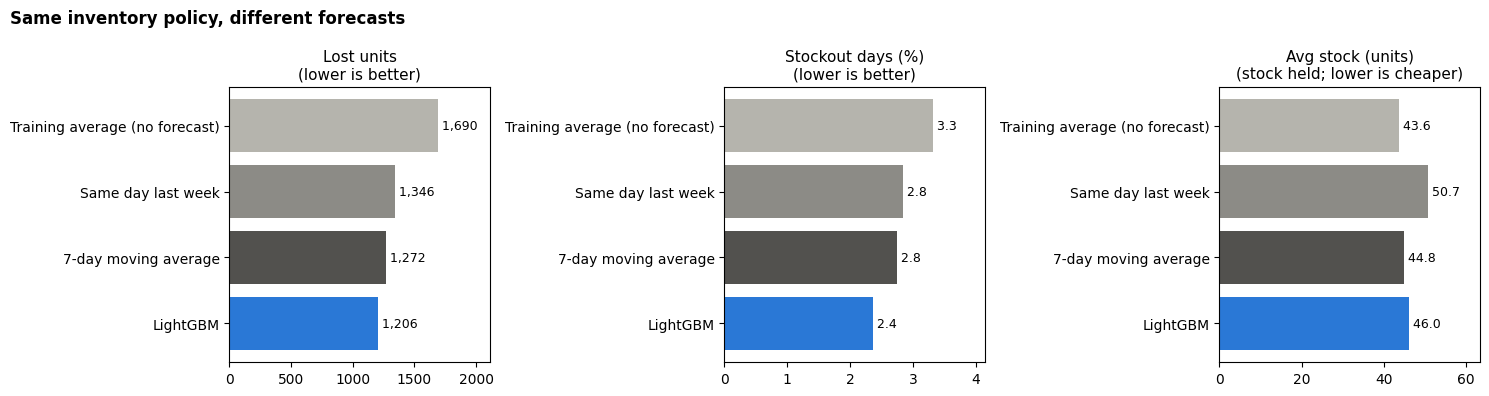

In [29]:
print("COMPARING FORECASTS IN THE SAME INVENTORY POLICY")
import io, contextlib

def run_policy(forecasts):
    """Run the inventory simulation with the given forecasts (one per forecast_data row); return its summary."""
    policy_df = forecast_data.assign(forecast=np.clip(np.nan_to_num(np.asarray(forecasts, dtype=float)), 0, None))
    with contextlib.redirect_stdout(io.StringIO()):   # the simulator's set-up messages were shown above
        sim = InventorySimulator(train_data, items, base_lead_time=3, service_level=0.95)
    for current_date in sorted(policy_df['date'].unique()):
        current_date = pd.Timestamp(current_date)
        sim.receive_orders(current_date)
        for row in policy_df[policy_df['date'] == current_date].itertuples(index=False):
            sim.simulate_sales_and_alert(row.item_nbr, row.store_nbr, row.forecast, None,
                                         actual=row.actual, current_date=current_date, is_open=row.is_open)
    return sim.summary(verbose=False)

training_mean = (forecast_data[['item_nbr', 'store_nbr']]
                 .merge(inventory_sim.inventory_levels['mean_daily_demand'].reset_index(),
                        on=['item_nbr', 'store_nbr'], how='left')['mean_daily_demand'].values)

policy_forecasts = {
    'Training average (no forecast)': training_mean,
    'Same day last week': test_data['sales_lag_7'].values,
    '7-day moving average': test_data['sales_ma_7'].values,
}
policy_results = {name: run_policy(fc) for name, fc in policy_forecasts.items()}
policy_results['LightGBM'] = inventory_summary      # the main simulation above

columns = ['Fill rate (%)', 'Stockout days (%)', 'Lost units', 'Expired units', 'Waste rate (%)', 'Avg stock (units)']
policy_comparison = pd.DataFrame({name: res.loc['All', columns] for name, res in policy_results.items()}).T
policy_comparison['Perishable fill rate (%)'] = [res.loc['Perishable', 'Fill rate (%)'] if 'Perishable' in res.index else np.nan
                                                 for res in policy_results.values()]
print("\nAll item-stores, open days:")
print(policy_comparison.round(1).to_string())

others = policy_comparison.drop(index='LightGBM')
best_other = others['Lost units'].idxmin()
lgbm = policy_comparison.loc['LightGBM']
print(f"\nLightGBM vs the best of the other forecasts ({best_other}):")
print(f"  Lost units: {lgbm['Lost units']:.0f} vs {others.loc[best_other, 'Lost units']:.0f} "
      f"({(lgbm['Lost units'] / others.loc[best_other, 'Lost units'] - 1) * 100:+.1f}%)")
print(f"  Avg stock:  {lgbm['Avg stock (units)']:.1f} vs {others.loc[best_other, 'Avg stock (units)']:.1f} units "
      f"({(lgbm['Avg stock (units)'] / others.loc[best_other, 'Avg stock (units)'] - 1) * 100:+.1f}%)")
print(f"  Waste:      {lgbm['Expired units']:.0f} vs {others.loc[best_other, 'Expired units']:.0f} units")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = ['#b5b4ad', '#8c8b86', '#52514e', '#2a78d6']
for ax, metric, note in zip(axes, ['Lost units', 'Stockout days (%)', 'Avg stock (units)'],
                            ['lower is better', 'lower is better', 'stock held; lower is cheaper']):
    vals = policy_comparison[metric]
    ax.barh(vals.index, vals.values, color=colors)
    for y, v in enumerate(vals.values):
        ax.text(v, y, f' {v:,.1f}' if v < 100 else f' {v:,.0f}', va='center', fontsize=9)
    ax.set_title(f'{metric}\n({note})', fontsize=11)
    ax.set_xlim(0, vals.max() * 1.25)
axes[0].invert_yaxis(); axes[1].invert_yaxis(); axes[2].invert_yaxis()
plt.suptitle('Same inventory policy, different forecasts', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.savefig('policy_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

### Print alert statistics

In [30]:
print("ALERT STATISTICS")

# Create an alerts dataframe for analysis
alerts_df = pd.DataFrame(alerts)

if not alerts_df.empty:
    n_routine = len(alert_system.routine_orders)
    print(f"\nReorders placed: {len(alerts_df) + n_routine} | routine (no alert): {n_routine} "
          f"| alerts for store managers: {len(alerts_df)}")
    print(f"\nLead-time demand as % of stock on hand + on order, at the time of the alert:")

    # Lead-time demand as a % of the stock on hand + on order (same measure as in the alerts, not capped here)
    alerts_df['available'] = alerts_df['inventory'] + alerts_df['on_order']
    alerts_df['lt_demand'] = alerts_df['forecast'] * alerts_df['lead_time']
    # Zero stock: any forecast demand means it runs out before delivery (shown as a very large ratio);
    # zero stock with zero forecast is 0%. This matches the urgency rule in AlertGenerator.assess.
    alerts_df['stockout_risk'] = np.where(
        alerts_df['available'] > 0,
        alerts_df['lt_demand'] / alerts_df['available'].where(alerts_df['available'] > 0) * 100,
        np.where(alerts_df['lt_demand'] > 0, 1e6, 0.0)
    )    
    alerts_df['risk_level'] = pd.cut(
        alerts_df['stockout_risk'],
        bins=[0, 80, 100, 150, float('inf')],
        labels=['<80%', '80-100%', '100-150%', '150%+'],
        right=False
    )

    print(alerts_df['risk_level'].value_counts().sort_index())
    print(f"\nAlert urgency:")
    print(alerts_df['urgency'].value_counts())
    
    # Urgency and the ratio bands measure the same thing with different cut-offs: CRITICAL means the stock
    # runs out before the new order arrives (ratio >= 100%); HIGH starts at 66.7% or when the stock on hand
    # plus on order is at or below safety stock. Routine (MEDIUM) reorders are not alerts, so they are not shown.
    print(f"\nUrgency by lead-time demand / stock band:")
    print(pd.crosstab(alerts_df['risk_level'], alerts_df['urgency'])
            .reindex(columns=['HIGH', 'CRITICAL'], fill_value=0))

    # Items by category
    alerts_with_items = alerts_df.merge(
        items[['item_nbr', 'family']],
        on=['item_nbr','family'],
        how='left'
    )

    print(f"\nAlerts by Product Category:")
    print(alerts_with_items['family'].value_counts())

    # Stores affected
    print(f"\nStores Requiring Attention:")
    print(alerts_df['store_nbr'].value_counts())

    # Potential Shortage: lead-time demand not covered by the stock on hand + on order when the alert was raised
    alerts_df['potential_shortage'] = (alerts_df['lt_demand'] - alerts_df['available']).clip(lower=0)
    print(f"\nTotal Potential Shortage (at time of alert): {alerts_df['potential_shortage'].sum():.0f} units")
else:
    print("No alerts were generated in this simulation run.")

ALERT STATISTICS

Reorders placed: 1939 | routine (no alert): 1198 | alerts for store managers: 741

Lead-time demand as % of stock on hand + on order, at the time of the alert:
risk_level
<80%        308
80-100%     193
100-150%    134
150%+       106
Name: count, dtype: int64

Alert urgency:
urgency
HIGH        501
CRITICAL    240
Name: count, dtype: int64

Urgency by lead-time demand / stock band:
urgency     HIGH  CRITICAL
risk_level                
<80%         308         0
80-100%      193         0
100-150%       0       134
150%+          0       106

Alerts by Product Category:
family
DAIRY        368
DELI         217
GROCERY I     75
BEVERAGES     50
CLEANING      31
Name: count, dtype: int64

Stores Requiring Attention:
store_nbr
31    106
7      98
24     88
48     83
5      69
2      69
16     59
40     58
19     56
9      55
Name: count, dtype: int64

Total Potential Shortage (at time of alert): 740 units


### Visualize alert insights

VISUALIZING ALERT INSIGHTS


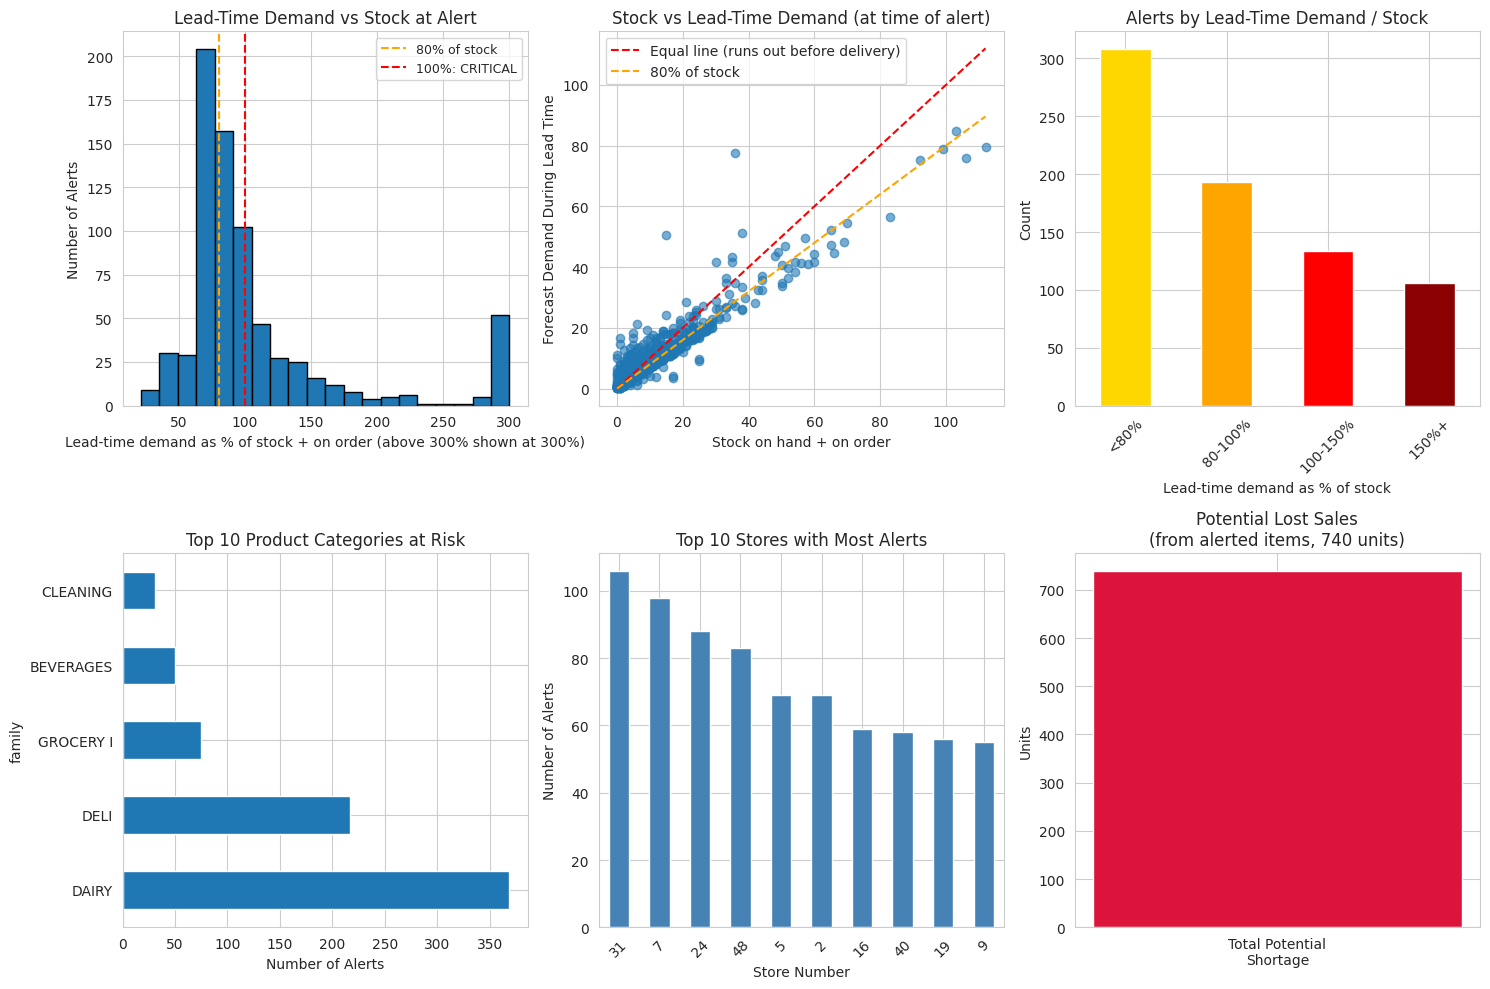

In [31]:
print("VISUALIZING ALERT INSIGHTS")

if not alerts_df.empty:
    # Set style
    sns.set_style("whitegrid")
    plt.figure(figsize=(15, 10))

    # 1. Stockout Risk Distribution
    plt.subplot(2, 3, 1)
    alerts_df['stockout_risk'].clip(upper=300).hist(bins=20, edgecolor='black')
    plt.xlabel('Lead-time demand as % of stock + on order (above 300% shown at 300%)')
    plt.ylabel('Number of Alerts')
    plt.title('Lead-Time Demand vs Stock at Alert')
    plt.axvline(x=80, color='orange', linestyle='--', label='80% of stock')
    plt.axvline(x=100, color='red', linestyle='--', label='100%: CRITICAL')
    plt.legend(loc='upper right', fontsize=9)

    # 2. Forecasted Demand vs Current Inventory
    plt.subplot(2, 3, 2)
    # Use inventory
    plt.scatter(alerts_df['available'], alerts_df['lt_demand'], alpha=0.6)
    max_val = max(alerts_df['available'].max(), alerts_df['lt_demand'].max())
    plt.plot([0, max_val], 
             [0, max_val], 
             'r--', label='Equal line (runs out before delivery)')
    plt.plot([0, max_val], 
             [0, max_val * 0.8], 
             '--', color='orange', label='80% of stock')
    plt.xlabel('Stock on hand + on order')
    plt.ylabel('Forecast Demand During Lead Time')
    plt.title('Stock vs Lead-Time Demand (at time of alert)')
    plt.legend()

    # 3. Risk Level Distribution
    plt.subplot(2, 3, 3)
    alerts_df['risk_level'].value_counts().sort_index().plot(kind='bar', color=['gold', 'orange', 'red', 'darkred'])
    plt.xlabel('Lead-time demand as % of stock')
    plt.ylabel('Count')
    plt.title('Alerts by Lead-Time Demand / Stock')
    plt.xticks(rotation=45)

    # 4. Top Categories at Risk
    plt.subplot(2, 3, 4)
    top_categories = alerts_with_items['family'].value_counts().head(10)
    top_categories.plot(kind='barh')
    plt.xlabel('Number of Alerts')
    plt.title('Top 10 Product Categories at Risk')

    # 5. Store-wise Alert Distribution
    plt.subplot(2, 3, 5)
    store_alerts = alerts_df['store_nbr'].value_counts().head(10)
    store_alerts.plot(kind='bar', color='steelblue')
    plt.xlabel('Store Number')
    plt.ylabel('Number of Alerts')
    plt.title('Top 10 Stores with Most Alerts')
    plt.xticks(rotation=45)

    # 6. Potential Lost Sales
    plt.subplot(2, 3, 6)
    # 'potential_shortage' was calculated in the previous cell
    total_shortage = alerts_df['potential_shortage'].sum()
    plt.bar(['Total Potential\nShortage'], [total_shortage], color='crimson')
    plt.ylabel('Units')
    plt.title(f'Potential Lost Sales\n(from alerted items, {total_shortage:.0f} units)')

    plt.tight_layout()
    plt.savefig('alert_analysis_dynamic.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print("Alerts DataFrame is empty. No visualizations to display.")